# OpenRVDAS JSON Ingestion (Step 1)
This cell scans the `OpenRVDAS` directory recursively, reads only `.json` files, and stores each parsed file in memory for downstream ETL and analysis steps.

In [72]:
from pathlib import Path
import json

# Workspace root is the parent folder containing OpenRVDAS
workspace_root = Path.cwd()
openrvdas_root = workspace_root / "OpenRVDAS"

if not openrvdas_root.exists():
    raise FileNotFoundError(f"Could not find folder: {openrvdas_root}")

# Filter to one day for initial development
target_date = "2021-07-04"
json_files = sorted(
    p for p in openrvdas_root.rglob("*.json")
    if p.name.endswith(f"-{target_date}.json")
)
print(f"Found {len(json_files)} JSON files in {openrvdas_root} for date {target_date}")

# Store loaded JSON payloads keyed by relative path
json_payloads = {}
failed_files = []

for file_path in json_files:
    rel_path = file_path.relative_to(workspace_root).as_posix()
    try:
        with file_path.open("r", encoding="utf-8") as f:
            json_payloads[rel_path] = json.load(f)
    except Exception as exc:
        failed_files.append((rel_path, str(exc)))

print(f"Successfully loaded: {len(json_payloads)}")
print(f"Failed to load: {len(failed_files)}")

if failed_files:
    print("\nFirst 10 failures:")
    for rel_path, err in failed_files[:10]:
        print(f"- {rel_path}: {err}")

# Optional quick peek at one loaded file
sample_key = next(iter(json_payloads), None)
if sample_key:
    print(f"\nSample loaded file: {sample_key}")
    print(f"Top-level keys: {list(json_payloads[sample_key].keys())[:10]}")

Found 14 JSON files in c:\Users\liuja\Desktop\oceanX_data\OpenRVDAS for date 2021-07-04
Successfully loaded: 14
Failed to load: 0

Sample loaded file: OpenRVDAS/proc/TrueWind_S1_Stbd-2021-07-04.json
Top-level keys: ['visualizerData', 'stats', 'qualityTests']


## Step 2: Normalize JSON payloads into a tidy table
This cell converts all loaded `json_payloads` into a long-format DataFrame with one row per observation and metadata columns for source file, variable label, and units.

In [73]:
import numpy as np
import pandas as pd

if "json_payloads" not in globals() or not json_payloads:
    raise RuntimeError("json_payloads is empty. Run Step 1 first.")

def _to_datetime_utc(series: pd.Series) -> pd.Series:
    numeric = pd.to_numeric(series, errors="coerce")
    if numeric.dropna().empty:
        return pd.to_datetime(series, errors="coerce", utc=True)
    max_abs = numeric.abs().max()
    unit = "ms" if max_abs > 1e11 else "s"
    return pd.to_datetime(numeric, unit=unit, errors="coerce", utc=True)

value_rows = []
geo_rows = []

for source_file, payload in json_payloads.items():
    visualizer_data = payload.get("visualizerData", [])
    if not isinstance(visualizer_data, list):
        continue

    for stream in visualizer_data:
        if not isinstance(stream, dict):
            continue

        # Case 1: standard timeseries stream with stream['data']
        label = stream.get("label", "unknown")
        unit = stream.get("unit")
        data_points = stream.get("data", [])

        if isinstance(data_points, list) and len(data_points) > 0:
            for point in data_points:
                ts_raw = None
                value_raw = None

                if isinstance(point, (list, tuple)) and len(point) >= 2:
                    ts_raw, value_raw = point[0], point[1]
                elif isinstance(point, dict):
                    for key in ("time", "timestamp", "t", "epoch", "seconds", "x"):
                        if key in point:
                            ts_raw = point[key]
                            break
                    for key in ("value", "y", "v", "measurement"):
                        if key in point:
                            value_raw = point[key]
                            break

                if ts_raw is None and value_raw is None:
                    continue

                value_rows.append({
                    "source_file": source_file,
                    "sensor_label": label,
                    "unit": unit,
                    "time_raw": ts_raw,
                    "value_raw": value_raw,
                })

        # Case 2: GeoJSON FeatureCollection track (e.g., Seapath_*_GGA)
        stream_type = stream.get("type")
        features = stream.get("features", [])
        if stream_type == "FeatureCollection" and isinstance(features, list):
            for feature in features:
                if not isinstance(feature, dict):
                    continue

                geometry = feature.get("geometry", {})
                properties = feature.get("properties", {})

                coordinates = geometry.get("coordinates", []) if isinstance(geometry, dict) else []
                coord_times = properties.get("coordTimes", []) if isinstance(properties, dict) else []

                if not isinstance(coordinates, list) or not isinstance(coord_times, list):
                    continue

                n = min(len(coordinates), len(coord_times))
                for i in range(n):
                    coord = coordinates[i]
                    ts_raw = coord_times[i]

                    if not isinstance(coord, (list, tuple)) or len(coord) < 2:
                        continue

                    lon_raw, lat_raw = coord[0], coord[1]
                    alt_raw = coord[2] if len(coord) > 2 else None

                    geo_rows.append({
                        "source_file": source_file,
                        "track_label": "GGA Track",
                        "time_raw": ts_raw,
                        "longitude_raw": lon_raw,
                        "latitude_raw": lat_raw,
                        "altitude_raw": alt_raw,
                    })

# Build scalar timeseries table
tidy_df = pd.DataFrame(value_rows)
if tidy_df.empty:
    raise RuntimeError("No scalar rows were extracted from visualizerData.")

tidy_df["time"] = _to_datetime_utc(tidy_df["time_raw"])
tidy_df["value"] = pd.to_numeric(tidy_df["value_raw"], errors="coerce")

tidy_df = tidy_df.dropna(subset=["time", "value"]).sort_values("time").reset_index(drop=True)

print(f"Scalar normalized rows: {len(tidy_df):,}")
print(f"Scalar files represented: {tidy_df['source_file'].nunique()}")
print(f"Scalar variables represented: {tidy_df['sensor_label'].nunique()}")
display(tidy_df.head())

dataset_summary = (
    tidy_df.groupby(["source_file", "sensor_label", "unit"], dropna=False)
    .agg(
        n=("value", "size"),
        t_min=("time", "min"),
        t_max=("time", "max"),
        v_min=("value", "min"),
        v_max=("value", "max"),
    )
    .reset_index()
    .sort_values(["source_file", "sensor_label"])
    .reset_index(drop=True)
)

print("\nPer-stream scalar summary preview:")
display(dataset_summary.head(20))

# Build geospatial table
geo_df = pd.DataFrame(geo_rows)
if geo_df.empty:
    print("\nGeospatial rows: 0 (no GeoJSON tracks found in current selection)")
else:
    geo_df["time"] = _to_datetime_utc(geo_df["time_raw"])
    geo_df["longitude"] = pd.to_numeric(geo_df["longitude_raw"], errors="coerce")
    geo_df["latitude"] = pd.to_numeric(geo_df["latitude_raw"], errors="coerce")
    geo_df["altitude"] = pd.to_numeric(geo_df["altitude_raw"], errors="coerce")

    geo_df = geo_df.dropna(subset=["time", "longitude", "latitude"]).sort_values("time").reset_index(drop=True)

    print(f"\nGeospatial rows: {len(geo_df):,}")
    print(f"Geospatial files represented: {geo_df['source_file'].nunique()}")
    display(geo_df.head())

    geo_summary = (
        geo_df.groupby(["source_file", "track_label"], dropna=False)
        .agg(
            n=("time", "size"),
            t_min=("time", "min"),
            t_max=("time", "max"),
            lon_min=("longitude", "min"),
            lon_max=("longitude", "max"),
            lat_min=("latitude", "min"),
            lat_max=("latitude", "max"),
        )
        .reset_index()
        .sort_values(["source_file", "track_label"])
)

    print("\nGeospatial summary preview:")
    display(geo_summary.head(20))

Scalar normalized rows: 40,320
Scalar files represented: 12
Scalar variables represented: 20


,source_file,sensor_label,unit,time_raw,value_raw,time,value
0,OpenRVDAS/raw/Stbd_Mast_Vaisala_MWV-2021-07-04...,Field 3,,1625356800000,8.708333,2021-07-04 00:00:00+00:00,8.708333
1,OpenRVDAS/raw/Stbd_Mast_Vaisala_MWV-2021-07-04...,Field 1,,1625356800000,138.166667,2021-07-04 00:00:00+00:00,138.166667
2,OpenRVDAS/raw/Seapath_2_VTG-2021-07-04.json,"SOG, kph",kph,1625356860000,20.530000,2021-07-04 00:01:00+00:00,20.530000
3,OpenRVDAS/raw/Bow_SBE45_TSG-2021-07-04.json,Internal Temp,C,1625356860000,20.796500,2021-07-04 00:01:00+00:00,20.796500
4,OpenRVDAS/raw/Wetlab_Transmissometer-2021-07-0...,Counts,Counts,1625356860000,12380.830000,2021-07-04 00:01:00+00:00,12380.830000



Per-stream scalar summary preview:


,source_file,sensor_label,unit,n,t_min,t_max,v_min,v_max
0,OpenRVDAS/proc/TrueWind_S1_Stbd-2021-07-04.json,"Wind Dir, True",deg,1440,2021-07-04 00:01:00+00:00,2021-07-05 00:00:00+00:00,109.60000,179.20000
1,OpenRVDAS/proc/TrueWind_S1_Stbd-2021-07-04.json,Wind Gust,m/s,1440,2021-07-04 00:01:00+00:00,2021-07-05 00:00:00+00:00,3.40000,13.80000
2,OpenRVDAS/proc/TrueWind_S1_Stbd-2021-07-04.json,Wind Lull,m/s,1440,2021-07-04 00:01:00+00:00,2021-07-05 00:00:00+00:00,0.80000,11.70000
3,OpenRVDAS/proc/TrueWind_S1_Stbd-2021-07-04.json,Wind Spd,m/s,1440,2021-07-04 00:01:00+00:00,2021-07-05 00:00:00+00:00,2.74000,12.59000
4,OpenRVDAS/proc/TrueWind_S2_Stbd-2021-07-04.json,"Wind Dir, True",deg,1440,2021-07-04 00:01:00+00:00,2021-07-05 00:00:00+00:00,109.60000,179.10000
5,OpenRVDAS/proc/TrueWind_S2_Stbd-2021-07-04.json,Wind Gust,m/s,1440,2021-07-04 00:01:00+00:00,2021-07-05 00:00:00+00:00,3.40000,13.80000
6,OpenRVDAS/proc/TrueWind_S2_Stbd-2021-07-04.json,Wind Lull,m/s,1440,2021-07-04 00:01:00+00:00,2021-07-05 00:00:00+00:00,0.80000,11.70000
7,OpenRVDAS/proc/TrueWind_S2_Stbd-2021-07-04.json,Wind Spd,m/s,1440,2021-07-04 00:01:00+00:00,2021-07-05 00:00:00+00:00,2.74000,12.59000
8,OpenRVDAS/raw/Bow_SBE45_TSG-2021-07-04.json,Conductivity,S/m,1440,2021-07-04 00:01:00+00:00,2021-07-05 00:00:00+00:00,4.67107,5.03472
9,OpenRVDAS/raw/Bow_SBE45_TSG-2021-07-04.json,External Temp,C,1440,2021-07-04 00:01:00+00:00,2021-07-05 00:00:00+00:00,18.04850,21.01560



Geospatial rows: 2,880
Geospatial files represented: 2


,source_file,track_label,time_raw,longitude_raw,latitude_raw,altitude_raw,time,longitude,latitude,altitude
0,OpenRVDAS/raw/Seapath_1_GGA-2021-07-04.json,GGA Track,1625356860000,-26.130797,38.760327,None,2021-07-04 00:01:00+00:00,-26.130797,38.760327,NaN
1,OpenRVDAS/raw/Seapath_2_GGA-2021-07-04.json,GGA Track,1625356860000,-26.130798,38.760330,None,2021-07-04 00:01:00+00:00,-26.130798,38.760330,NaN
2,OpenRVDAS/raw/Seapath_2_GGA-2021-07-04.json,GGA Track,1625356920000,-26.131502,38.763326,None,2021-07-04 00:02:00+00:00,-26.131502,38.763326,NaN
3,OpenRVDAS/raw/Seapath_1_GGA-2021-07-04.json,GGA Track,1625356920000,-26.131501,38.763322,None,2021-07-04 00:02:00+00:00,-26.131501,38.763322,NaN
4,OpenRVDAS/raw/Seapath_1_GGA-2021-07-04.json,GGA Track,1625356980000,-26.132190,38.766274,None,2021-07-04 00:03:00+00:00,-26.132190,38.766274,NaN



Geospatial summary preview:


,source_file,track_label,n,t_min,t_max,lon_min,lon_max,lat_min,lat_max
0,OpenRVDAS/raw/Seapath_1_GGA-2021-07-04.json,GGA Track,1440,2021-07-04 00:01:00+00:00,2021-07-05 00:00:00+00:00,-26.877571,-26.130797,38.760327,42.768864
1,OpenRVDAS/raw/Seapath_2_GGA-2021-07-04.json,GGA Track,1440,2021-07-04 00:01:00+00:00,2021-07-05 00:00:00+00:00,-26.877570,-26.130798,38.760330,42.768868


In [74]:
loaded_files = set(json_payloads.keys())
represented_files = set(tidy_df["source_file"].unique())

missing_files = sorted(loaded_files - represented_files)
print(f"Loaded files: {len(loaded_files)}")
print(f"Represented files: {len(represented_files)}")
print(f"Missing from tidy_df: {len(missing_files)}")

for path in missing_files:
    payload = json_payloads[path]
    streams = payload.get("visualizerData", []) if isinstance(payload, dict) else []
    stream_count = len(streams) if isinstance(streams, list) else 0
    point_count = 0
    for stream in streams if isinstance(streams, list) else []:
        data = stream.get("data", []) if isinstance(stream, dict) else []
        if isinstance(data, list):
            point_count += len(data)
    print(f"- {path} | streams={stream_count}, raw_points={point_count}")

Loaded files: 14
Represented files: 12
Missing from tidy_df: 2
- OpenRVDAS/raw/Seapath_1_GGA-2021-07-04.json | streams=1, raw_points=0
- OpenRVDAS/raw/Seapath_2_GGA-2021-07-04.json | streams=1, raw_points=0


## Step 3: Quick geospatial plot + speed estimate
This cell plots vessel tracks from `geo_df` and estimates speed-over-ground from point-to-point distance and elapsed time.

Rows with speed estimate: 2,878


,source_file,n,mean,median,max
0,OpenRVDAS/raw/Seapath_1_GGA-2021-07-04.json,1439,10.739,10.74,12.701
1,OpenRVDAS/raw/Seapath_2_GGA-2021-07-04.json,1439,10.739,10.74,12.701


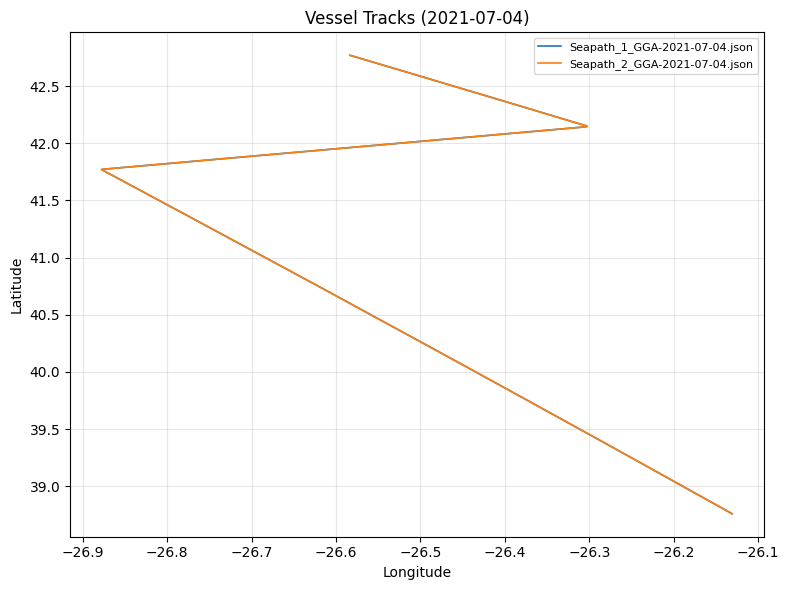

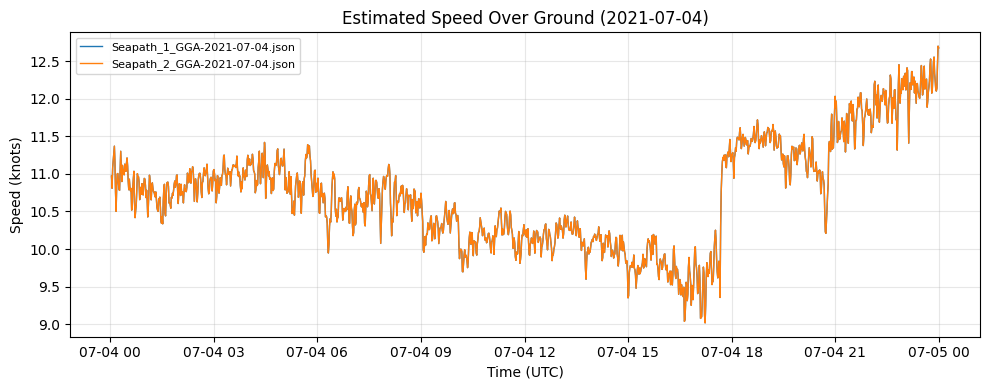

In [75]:
import matplotlib.pyplot as plt
import numpy as np

if "geo_df" not in globals() or geo_df.empty:
    raise RuntimeError("geo_df is empty. Run Step 2 first.")

R_EARTH_M = 6371000.0
MPS_TO_KNOTS = 1.9438444924406

def haversine_m(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = np.radians([lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return R_EARTH_M * c

geo_speed_parts = []

for source_file, group in geo_df.groupby("source_file", sort=True):
    track = group.sort_values("time").copy()

    track["lon_prev"] = track["longitude"].shift(1)
    track["lat_prev"] = track["latitude"].shift(1)
    track["time_prev"] = track["time"].shift(1)

    dt_s = (track["time"] - track["time_prev"]).dt.total_seconds()
    dist_m = haversine_m(
        track["lon_prev"].fillna(track["longitude"]),
        track["lat_prev"].fillna(track["latitude"]),
        track["longitude"],
        track["latitude"],
    )

    track["distance_m"] = np.where(dt_s > 0, dist_m, np.nan)
    track["dt_s"] = np.where(dt_s > 0, dt_s, np.nan)
    track["speed_mps"] = track["distance_m"] / track["dt_s"]
    track["speed_knots"] = track["speed_mps"] * MPS_TO_KNOTS

    geo_speed_parts.append(track[[
        "source_file", "time", "longitude", "latitude",
        "distance_m", "dt_s", "speed_mps", "speed_knots"
    ]])

geo_speed_df = pd.concat(geo_speed_parts, ignore_index=True)

print(f"Rows with speed estimate: {geo_speed_df['speed_mps'].notna().sum():,}")
display(
    geo_speed_df.groupby("source_file", dropna=False)["speed_knots"]
    .agg(["count", "mean", "median", "max"])
    .rename(columns={"count": "n"})
    .round(3)
    .reset_index()
    )

# Plot 1: track map (lon/lat)
plt.figure(figsize=(8, 6))
for source_file, group in geo_speed_df.groupby("source_file", sort=True):
    plt.plot(group["longitude"], group["latitude"], label=source_file.split("/")[-1], linewidth=1.2)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(f"Vessel Tracks ({target_date})")
plt.legend(loc="best", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Plot 2: speed over time (knots)
plt.figure(figsize=(10, 4))
for source_file, group in geo_speed_df.groupby("source_file", sort=True):
    plt.plot(group["time"], group["speed_knots"], label=source_file.split("/")[-1], linewidth=1.0)
plt.xlabel("Time (UTC)")
plt.ylabel("Speed (knots)")
plt.title(f"Estimated Speed Over Ground ({target_date})")
plt.legend(loc="best", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 4: Export geospatial speed dataset to Parquet
This cell writes the `geo_speed_df` table to a reusable Parquet file for downstream analysis and DuckDB queries.

In [76]:
from pathlib import Path

if "geo_speed_df" not in globals() or geo_speed_df.empty:
    raise RuntimeError("geo_speed_df is empty. Run Step 3 first.")

output_dir = Path.cwd() / "data" / f"cruise_{target_date.replace('-', '_')}"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "navigation_geo_speed.parquet"
geo_speed_df.to_parquet(output_path, index=False)

print(f"Saved: {output_path}")
print(f"Rows written: {len(geo_speed_df):,}")
print("Columns:")
print(list(geo_speed_df.columns))

Saved: c:\Users\liuja\Desktop\oceanX_data\data\cruise_2021_07_04\navigation_geo_speed.parquet
Rows written: 2,880
Columns:
['source_file', 'time', 'longitude', 'latitude', 'distance_m', 'dt_s', 'speed_mps', 'speed_knots']


## Step 5: Export normalized datasets
This cell exports scalar and geospatial normalized tables to Parquet so the data lake has reusable base datasets.

In [77]:
from pathlib import Path

if "tidy_df" not in globals() or tidy_df.empty:
    raise RuntimeError("tidy_df is empty. Run Step 2 first.")
if "geo_df" not in globals() or geo_df.empty:
    raise RuntimeError("geo_df is empty. Run Step 2 first.")

lake_dir = Path.cwd() / "data" / f"cruise_{target_date.replace('-', '_')}"
lake_dir.mkdir(parents=True, exist_ok=True)

scalar_path = lake_dir / "scalar_timeseries.parquet"
geo_path = lake_dir / "navigation_track.parquet"

tidy_df.to_parquet(scalar_path, index=False)
geo_df.to_parquet(geo_path, index=False)

print(f"Saved scalar dataset: {scalar_path}")
print(f"Rows: {len(tidy_df):,}")
print(f"Saved geospatial dataset: {geo_path}")
print(f"Rows: {len(geo_df):,}")

Saved scalar dataset: c:\Users\liuja\Desktop\oceanX_data\data\cruise_2021_07_04\scalar_timeseries.parquet
Rows: 40,320
Saved geospatial dataset: c:\Users\liuja\Desktop\oceanX_data\data\cruise_2021_07_04\navigation_track.parquet
Rows: 2,880


## Step 6: Generate metadata file
This cell writes a lightweight metadata.yaml describing dataset scope, variables, and source files for reproducibility.

In [78]:
from pathlib import Path

if "lake_dir" not in globals():
    lake_dir = Path.cwd() / "data" / f"cruise_{target_date.replace('-', '_')}"
    lake_dir.mkdir(parents=True, exist_ok=True)

metadata_text = f"""cruise: cruise_{target_date.replace('-', '_')}
date: {target_date}
source_root: OpenRVDAS

files:
  scalar_dataset: scalar_timeseries.parquet
  geospatial_dataset: navigation_track.parquet
  geospatial_speed_dataset: navigation_geo_speed.parquet

counts:
  loaded_json_files: {len(json_payloads)}
  scalar_rows: {len(tidy_df)}
  geospatial_rows: {len(geo_df)}
  geospatial_speed_rows: {len(geo_speed_df)}

variables:
  scalar_labels: {sorted(tidy_df['sensor_label'].dropna().unique().tolist())}
  geospatial_columns: {['time','longitude','latitude','altitude']}
"""

metadata_path = lake_dir / "metadata.yaml"
metadata_path.write_text(metadata_text, encoding="utf-8")

print(f"Saved metadata: {metadata_path}")
print(metadata_text.splitlines()[:10])

Saved metadata: c:\Users\liuja\Desktop\oceanX_data\data\cruise_2021_07_04\metadata.yaml
['cruise: cruise_2021_07_04', 'date: 2021-07-04', 'source_root: OpenRVDAS', '', 'files:', '  scalar_dataset: scalar_timeseries.parquet', '  geospatial_dataset: navigation_track.parquet', '  geospatial_speed_dataset: navigation_geo_speed.parquet', '', 'counts:']


## Step 7: DuckDB validation queries
This cell runs SQL checks directly against Parquet outputs to validate row counts and basic speed statistics.

In [79]:
import duckdb

if "lake_dir" not in globals():
    raise RuntimeError("lake_dir not found. Run Step 5 first.")

scalar_path = lake_dir / "scalar_timeseries.parquet"
geo_path = lake_dir / "navigation_track.parquet"
geo_speed_path = lake_dir / "navigation_geo_speed.parquet"

con = duckdb.connect()

row_counts_sql = f"""
SELECT 'scalar_timeseries' AS dataset, COUNT(*) AS n FROM read_parquet('{scalar_path.as_posix()}')
UNION ALL
SELECT 'navigation_track' AS dataset, COUNT(*) AS n FROM read_parquet('{geo_path.as_posix()}')
UNION ALL
SELECT 'navigation_geo_speed' AS dataset, COUNT(*) AS n FROM read_parquet('{geo_speed_path.as_posix()}')
"""
row_counts_df = con.execute(row_counts_sql).df()
print("Row counts:")
display(row_counts_df)

speed_sql = f"""
SELECT
  source_file,
  COUNT(speed_knots) AS n,
  ROUND(AVG(speed_knots), 3) AS mean_knots,
  ROUND(MEDIAN(speed_knots), 3) AS median_knots,
  ROUND(MAX(speed_knots), 3) AS max_knots
FROM read_parquet('{geo_speed_path.as_posix()}')
GROUP BY source_file
ORDER BY source_file
"""
speed_stats_df = con.execute(speed_sql).df()
print("\nSpeed summary from DuckDB:")
display(speed_stats_df)

con.close()

Row counts:


,dataset,n
0,scalar_timeseries,40320
1,navigation_track,2880
2,navigation_geo_speed,2880



Speed summary from DuckDB:


,source_file,n,mean_knots,median_knots,max_knots
0,OpenRVDAS/raw/Seapath_1_GGA-2021-07-04.json,1439,10.739,10.74,12.701
1,OpenRVDAS/raw/Seapath_2_GGA-2021-07-04.json,1439,10.739,10.74,12.701


## Step 8: One-command daily pipeline
Use `run_daily_pipeline('YYYY-MM-DD')` to execute ingestion, normalization, speed estimation, Parquet exports, metadata generation, and DuckDB validation in one call.

In [80]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import duckdb

R_EARTH_M = 6371000.0
MPS_TO_KNOTS = 1.9438444924406

def _to_datetime_utc(series: pd.Series) -> pd.Series:
    numeric = pd.to_numeric(series, errors="coerce")
    if numeric.dropna().empty:
        return pd.to_datetime(series, errors="coerce", utc=True)
    max_abs = numeric.abs().max()
    unit = "ms" if max_abs > 1e11 else "s"
    return pd.to_datetime(numeric, unit=unit, errors="coerce", utc=True)

def _haversine_m(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = np.radians([lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return R_EARTH_M * c

def run_daily_pipeline(target_date: str, workspace_root: Path | None = None):
    if workspace_root is None:
        workspace_root = Path.cwd()
    openrvdas_root = workspace_root / "OpenRVDAS"
    if not openrvdas_root.exists():
        raise FileNotFoundError(f"Could not find folder: {openrvdas_root}")

    json_files = sorted(
        p for p in openrvdas_root.rglob("*.json")
        if p.name.endswith(f"-{target_date}.json")
    )

    json_payloads = {}
    failed_files = []
    for file_path in json_files:
        rel_path = file_path.relative_to(workspace_root).as_posix()
        try:
            with file_path.open("r", encoding="utf-8") as f:
                json_payloads[rel_path] = json.load(f)
        except Exception as exc:
            failed_files.append((rel_path, str(exc)))

    value_rows = []
    geo_rows = []

    for source_file, payload in json_payloads.items():
        visualizer_data = payload.get("visualizerData", [])
        if not isinstance(visualizer_data, list):
            continue

        for stream in visualizer_data:
            if not isinstance(stream, dict):
                continue

            label = stream.get("label", "unknown")
            unit = stream.get("unit")
            data_points = stream.get("data", [])

            if isinstance(data_points, list) and len(data_points) > 0:
                for point in data_points:
                    ts_raw = None
                    value_raw = None
                    if isinstance(point, (list, tuple)) and len(point) >= 2:
                        ts_raw, value_raw = point[0], point[1]
                    elif isinstance(point, dict):
                        for key in ("time", "timestamp", "t", "epoch", "seconds", "x"):
                            if key in point:
                                ts_raw = point[key]
                                break
                        for key in ("value", "y", "v", "measurement"):
                            if key in point:
                                value_raw = point[key]
                                break
                    if ts_raw is None and value_raw is None:
                        continue
                    value_rows.append({
                        "source_file": source_file,
                        "sensor_label": label,
                        "unit": unit,
                        "time_raw": ts_raw,
                        "value_raw": value_raw,
                    })

            if stream.get("type") == "FeatureCollection" and isinstance(stream.get("features"), list):
                for feature in stream["features"]:
                    if not isinstance(feature, dict):
                        continue
                    geometry = feature.get("geometry", {})
                    properties = feature.get("properties", {})
                    coordinates = geometry.get("coordinates", []) if isinstance(geometry, dict) else []
                    coord_times = properties.get("coordTimes", []) if isinstance(properties, dict) else []
                    if not isinstance(coordinates, list) or not isinstance(coord_times, list):
                        continue
                    n = min(len(coordinates), len(coord_times))
                    for i in range(n):
                        coord = coordinates[i]
                        ts_raw = coord_times[i]
                        if not isinstance(coord, (list, tuple)) or len(coord) < 2:
                            continue
                        lon_raw, lat_raw = coord[0], coord[1]
                        alt_raw = coord[2] if len(coord) > 2 else None
                        geo_rows.append({
                            "source_file": source_file,
                            "track_label": "GGA Track",
                            "time_raw": ts_raw,
                            "longitude_raw": lon_raw,
                            "latitude_raw": lat_raw,
                            "altitude_raw": alt_raw,
                        })

    tidy_df = pd.DataFrame(value_rows)
    if tidy_df.empty:
        raise RuntimeError("No scalar rows extracted for this date.")
    tidy_df["time"] = _to_datetime_utc(tidy_df["time_raw"])
    tidy_df["value"] = pd.to_numeric(tidy_df["value_raw"], errors="coerce")
    tidy_df = tidy_df.dropna(subset=["time", "value"]).sort_values("time").reset_index(drop=True)

    geo_df = pd.DataFrame(geo_rows)
    if not geo_df.empty:
        geo_df["time"] = _to_datetime_utc(geo_df["time_raw"])
        geo_df["longitude"] = pd.to_numeric(geo_df["longitude_raw"], errors="coerce")
        geo_df["latitude"] = pd.to_numeric(geo_df["latitude_raw"], errors="coerce")
        geo_df["altitude"] = pd.to_numeric(geo_df["altitude_raw"], errors="coerce")
        geo_df = geo_df.dropna(subset=["time", "longitude", "latitude"]).sort_values("time").reset_index(drop=True)

    geo_speed_parts = []
    if not geo_df.empty:
        for source_file, group in geo_df.groupby("source_file", sort=True):
            track = group.sort_values("time").copy()
            track["lon_prev"] = track["longitude"].shift(1)
            track["lat_prev"] = track["latitude"].shift(1)
            track["time_prev"] = track["time"].shift(1)
            dt_s = (track["time"] - track["time_prev"]).dt.total_seconds()
            dist_m = _haversine_m(
                track["lon_prev"].fillna(track["longitude"]),
                track["lat_prev"].fillna(track["latitude"]),
                track["longitude"],
                track["latitude"],
            )
            track["distance_m"] = np.where(dt_s > 0, dist_m, np.nan)
            track["dt_s"] = np.where(dt_s > 0, dt_s, np.nan)
            track["speed_mps"] = track["distance_m"] / track["dt_s"]
            track["speed_knots"] = track["speed_mps"] * MPS_TO_KNOTS
            geo_speed_parts.append(track[[
                "source_file", "time", "longitude", "latitude",
                "distance_m", "dt_s", "speed_mps", "speed_knots"
            ]])
    geo_speed_df = pd.concat(geo_speed_parts, ignore_index=True) if geo_speed_parts else pd.DataFrame(
        columns=["source_file", "time", "longitude", "latitude", "distance_m", "dt_s", "speed_mps", "speed_knots"]
)

    lake_dir = workspace_root / "data" / f"cruise_{target_date.replace('-', '_')}"
    lake_dir.mkdir(parents=True, exist_ok=True)

    scalar_path = lake_dir / "scalar_timeseries.parquet"
    geo_path = lake_dir / "navigation_track.parquet"
    geo_speed_path = lake_dir / "navigation_geo_speed.parquet"
    metadata_path = lake_dir / "metadata.yaml"

    tidy_df.to_parquet(scalar_path, index=False)
    geo_df.to_parquet(geo_path, index=False)
    geo_speed_df.to_parquet(geo_speed_path, index=False)

    metadata_text = f"""cruise: cruise_{target_date.replace('-', '_')}
date: {target_date}
source_root: OpenRVDAS

files:
  scalar_dataset: scalar_timeseries.parquet
  geospatial_dataset: navigation_track.parquet
  geospatial_speed_dataset: navigation_geo_speed.parquet

counts:
  loaded_json_files: {len(json_payloads)}
  failed_json_files: {len(failed_files)}
  scalar_rows: {len(tidy_df)}
  geospatial_rows: {len(geo_df)}
  geospatial_speed_rows: {len(geo_speed_df)}
"""
    metadata_path.write_text(metadata_text, encoding="utf-8")

    con = duckdb.connect()
    row_counts_df = con.execute(f"""
        SELECT 'scalar_timeseries' AS dataset, COUNT(*) AS n FROM read_parquet('{scalar_path.as_posix()}')
        UNION ALL
        SELECT 'navigation_track' AS dataset, COUNT(*) AS n FROM read_parquet('{geo_path.as_posix()}')
        UNION ALL
        SELECT 'navigation_geo_speed' AS dataset, COUNT(*) AS n FROM read_parquet('{geo_speed_path.as_posix()}')
    """).df()
    con.close()

    summary = {
        "target_date": target_date,
        "loaded_json_files": len(json_payloads),
        "failed_json_files": len(failed_files),
        "scalar_rows": len(tidy_df),
        "geospatial_rows": len(geo_df),
        "geospatial_speed_rows": len(geo_speed_df),
        "lake_dir": str(lake_dir),
    }

    print("Pipeline complete:")
    print(summary)
    display(row_counts_df)

    return {
        "summary": summary,
        "row_counts_df": row_counts_df,
        "scalar_path": scalar_path,
        "geo_path": geo_path,
        "geo_speed_path": geo_speed_path,
        "metadata_path": metadata_path,
        "failed_files": failed_files,
    }

pipeline_result = run_daily_pipeline("2021-07-04")

Pipeline complete:
{'target_date': '2021-07-04', 'loaded_json_files': 14, 'failed_json_files': 0, 'scalar_rows': 40320, 'geospatial_rows': 2880, 'geospatial_speed_rows': 2880, 'lake_dir': 'c:\\Users\\liuja\\Desktop\\oceanX_data\\data\\cruise_2021_07_04'}


,dataset,n
0,scalar_timeseries,40320
1,navigation_track,2880
2,navigation_geo_speed,2880


## Step 9: Example analysis tools (DuckDB + Parquet)
This section defines reusable analysis tools on top of the exported Parquet datasets.
Tools included: correlation matrix, lag correlation, trend analysis, and z-score anomaly detection.

Available labels (20): ['Barometer', 'COG, True', 'Chlorophyll Signal', 'Conductivity', 'Counts', 'External Temp', 'Field 1', 'Field 3', 'Flowrate', 'Heading', 'Humidity', 'Internal Temp', 'SOG, kph', 'SOG, kts', 'Salinity', 'Temperature', 'Wind Dir, True', 'Wind Gust', 'Wind Lull', 'Wind Spd']

Demo pair for correlation/lag: ['Wind Spd', 'Salinity']


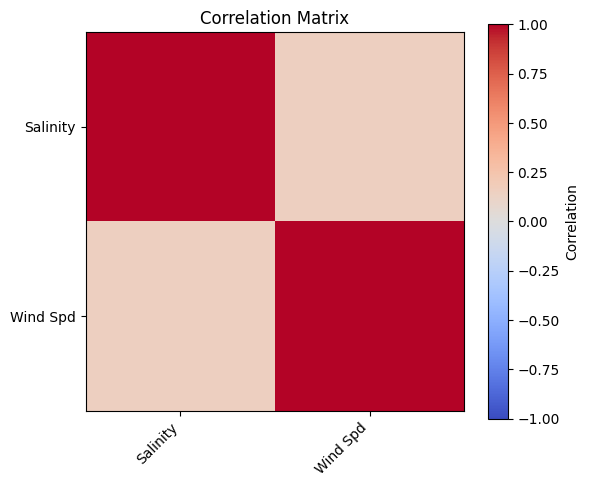

sensor_label,Salinity,Wind Spd
sensor_label,,
Salinity,1.000000,0.150082
Wind Spd,0.150082,1.000000


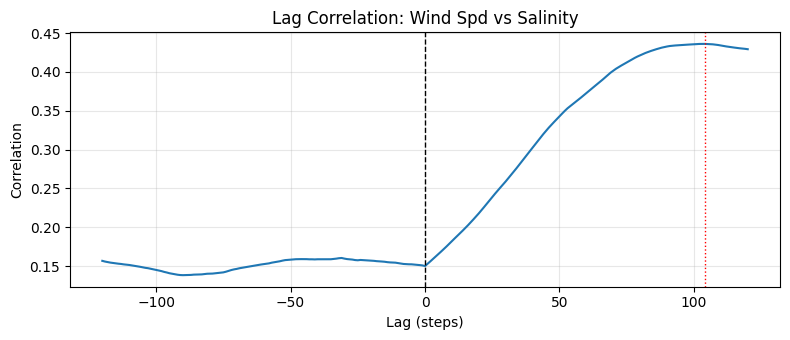

Best lag (steps): 104, corr=0.4360


,lag_steps,corr
0,-120,0.156750
1,-119,0.155822
2,-118,0.155134
3,-117,0.154478
4,-116,0.153968


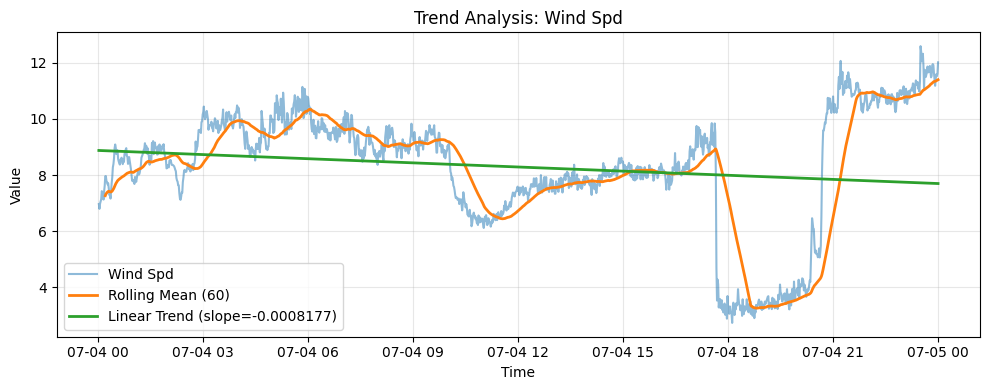

Trend stats: {'slope': -0.0008177419931079572, 'intercept': 8.87709105848562, 'n': 1440}


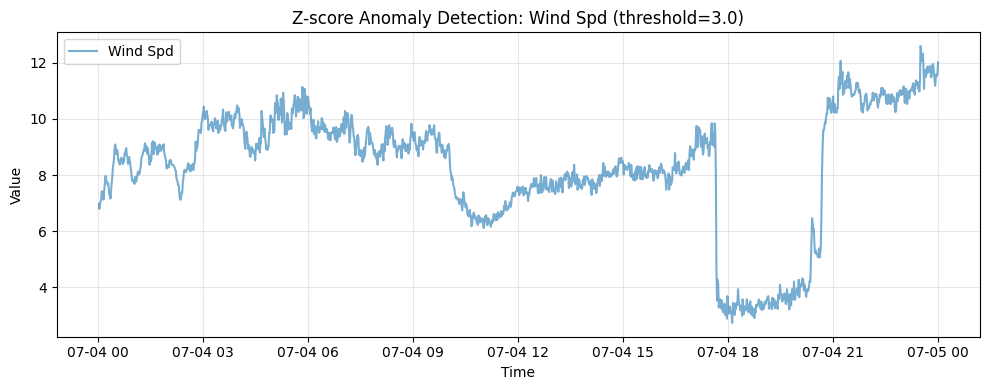

Anomalies detected for Wind Spd: 0


,time,value,zscore


In [81]:
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt

if "lake_dir" not in globals():
    raise RuntimeError("lake_dir not found. Run Step 8 first.")

scalar_path = lake_dir / "scalar_timeseries.parquet"

def get_available_scalar_labels(parquet_path):
    con = duckdb.connect()
    labels = con.execute(
        f"SELECT DISTINCT sensor_label FROM read_parquet('{parquet_path.as_posix()}') ORDER BY sensor_label"
    ).df()["sensor_label"].tolist()
    con.close()
    return labels

def load_scalar_timeseries(parquet_path, labels, start_time=None, end_time=None):
    labels_sql = ", ".join(["'" + lbl.replace("'", "''") + "'" for lbl in labels])
    where_parts = [f"sensor_label IN ({labels_sql})"]
    if start_time is not None:
        where_parts.append(f"time >= '{pd.Timestamp(start_time).isoformat()}'")
    if end_time is not None:
        where_parts.append(f"time <= '{pd.Timestamp(end_time).isoformat()}'")
    where_sql = " AND ".join(where_parts)

    query = f"""
    SELECT time, sensor_label, value
    FROM read_parquet('{parquet_path.as_posix()}')
    WHERE {where_sql}
    ORDER BY time
    """
    con = duckdb.connect()
    df = con.execute(query).df()
    con.close()

    if df.empty:
        return df

    df["time"] = pd.to_datetime(df["time"], utc=True, errors="coerce")
    wide_df = (
        df.pivot_table(index="time", columns="sensor_label", values="value", aggfunc="mean")
        .sort_index()
    )
    return wide_df

def correlation_tool(parquet_path, labels):
    wide_df = load_scalar_timeseries(parquet_path, labels)
    corr = wide_df.corr()

    plt.figure(figsize=(6, 5))
    im = plt.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
    plt.colorbar(im, label="Correlation")
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
    plt.yticks(range(len(corr.index)), corr.index)
    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.show()

    return corr

def lag_correlation_tool(parquet_path, x_label, y_label, max_lag_steps=120):
    wide_df = load_scalar_timeseries(parquet_path, [x_label, y_label]).dropna()
    if wide_df.empty:
        raise RuntimeError("No overlapping data for lag correlation.")

    x = wide_df[x_label]
    y = wide_df[y_label]

    lags = np.arange(-max_lag_steps, max_lag_steps + 1)
    corr_vals = []
    for lag in lags:
        corr_vals.append(x.corr(y.shift(lag)))

    lag_df = pd.DataFrame({"lag_steps": lags, "corr": corr_vals})
    best_row = lag_df.iloc[lag_df["corr"].abs().idxmax()]

    plt.figure(figsize=(8, 3.5))
    plt.plot(lag_df["lag_steps"], lag_df["corr"])
    plt.axvline(0, color="black", linestyle="--", linewidth=1)
    plt.axvline(best_row["lag_steps"], color="red", linestyle=":", linewidth=1)
    plt.title(f"Lag Correlation: {x_label} vs {y_label}")
    plt.xlabel("Lag (steps)")
    plt.ylabel("Correlation")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return lag_df, int(best_row["lag_steps"]), float(best_row["corr"])
,
def trend_tool(parquet_path, label, rolling_window=60):
    wide_df = load_scalar_timeseries(parquet_path, [label]).dropna()
    if wide_df.empty:
        raise RuntimeError("No data for trend analysis.")

    s = wide_df[label]
    rolling = s.rolling(rolling_window, min_periods=max(3, rolling_window // 5)).mean()

    x = np.arange(len(s))
    slope, intercept = np.polyfit(x, s.values, 1)
    trend_line = intercept + slope * x

    plt.figure(figsize=(10, 4))
    plt.plot(s.index, s.values, label=label, alpha=0.5)
    plt.plot(s.index, rolling.values, label=f"Rolling Mean ({rolling_window})", linewidth=2)
    plt.plot(s.index, trend_line, label=f"Linear Trend (slope={slope:.4g})", linewidth=2)
    plt.title(f"Trend Analysis: {label}")
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return {"slope": float(slope), "intercept": float(intercept), "n": int(len(s))}

def anomaly_detection_tool(parquet_path, label, z_threshold=3.0):
    wide_df = load_scalar_timeseries(parquet_path, [label]).dropna()
    if wide_df.empty:
        raise RuntimeError("No data for anomaly detection.")

    s = wide_df[label]
    z = (s - s.mean()) / s.std(ddof=0)
    anomalies = pd.DataFrame({"time": s.index, "value": s.values, "zscore": z.values})
    anomalies = anomalies[anomalies["zscore"].abs() >= z_threshold].copy()

    plt.figure(figsize=(10, 4))
    plt.plot(s.index, s.values, label=label, alpha=0.6)
    if not anomalies.empty:
        plt.scatter(anomalies["time"], anomalies["value"], color="red", s=20, label="Anomaly")
    plt.title(f"Z-score Anomaly Detection: {label} (threshold={z_threshold})")
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return anomalies.sort_values("zscore", key=lambda col: col.abs(), ascending=False)

# --- Demo run ---
available_labels = get_available_scalar_labels(scalar_path)
print(f"Available labels ({len(available_labels)}):", available_labels)

demo_pair = [lbl for lbl in ["Wind Spd", "Salinity"] if lbl in available_labels]
if len(demo_pair) < 2:
    demo_pair = available_labels[:2]

print(f"\nDemo pair for correlation/lag: {demo_pair}")
corr_df = correlation_tool(scalar_path, demo_pair)
display(corr_df)

lag_df, best_lag, best_corr = lag_correlation_tool(scalar_path, demo_pair[0], demo_pair[1], max_lag_steps=120)
print(f"Best lag (steps): {best_lag}, corr={best_corr:.4f}")
display(lag_df.head())

trend_label = demo_pair[0]
trend_stats = trend_tool(scalar_path, trend_label, rolling_window=60)
print("Trend stats:", trend_stats)

anomaly_df = anomaly_detection_tool(scalar_path, trend_label, z_threshold=3.0)
print(f"Anomalies detected for {trend_label}: {len(anomaly_df)}")
display(anomaly_df.head(10))

## Step 10: Example natural-language query
Question: **When was salinity the highest?**
This cell answers it using DuckDB SQL over `scalar_timeseries.parquet`.

In [82]:
import duckdb

if "scalar_path" not in globals():
    scalar_path = lake_dir / "scalar_timeseries.parquet"

con = duckdb.connect()

query_peak_salinity = f"""
SELECT
  time,
  value AS salinity,
  source_file
FROM read_parquet('{scalar_path.as_posix()}')
WHERE sensor_label = 'Salinity'
ORDER BY salinity DESC, time ASC
LIMIT 1
"""

peak_salinity_df = con.execute(query_peak_salinity).df()
con.close()

if peak_salinity_df.empty:
    print("No salinity rows found.")
else:
    peak_row = peak_salinity_df.iloc[0]
    print(f"Highest salinity: {peak_row['salinity']:.5f}")
    print(f"Time (UTC): {peak_row['time']}")
    print(f"Source file: {peak_row['source_file']}")
    display(peak_salinity_df)

Highest salinity: 36.13810
Time (UTC): 2021-07-03 21:45:00-04:00
Source file: OpenRVDAS/raw/Bow_SBE45_TSG-2021-07-04.json


,time,salinity,source_file
0,2021-07-03 21:45:00-04:00,36.1381,OpenRVDAS/raw/Bow_SBE45_TSG-2021-07-04.json


## Step 11: More natural-language query examples
These examples show how scientist-style questions map to DuckDB SQL on Parquet.

In [83]:
import duckdb
import pandas as pd

if "scalar_path" not in globals():
    scalar_path = lake_dir / "scalar_timeseries.parquet"

con = duckdb.connect()

queries = {
    "When was wind speed the lowest?": f"""
        SELECT time, value AS wind_spd, source_file
        FROM read_parquet('{scalar_path.as_posix()}')
        WHERE sensor_label = 'Wind Spd'
        ORDER BY wind_spd ASC, time ASC
        LIMIT 1
    """,
    "When was chlorophyll highest?": f"""
        SELECT time, value AS chlorophyll, source_file
        FROM read_parquet('{scalar_path.as_posix()}')
        WHERE sensor_label = 'Chlorophyll Signal'
        ORDER BY chlorophyll DESC, time ASC
        LIMIT 1
    """,
    "Top 5 salinity peaks": f"""
        SELECT time, value AS salinity, source_file
        FROM read_parquet('{scalar_path.as_posix()}')
        WHERE sensor_label = 'Salinity'
        ORDER BY salinity DESC, time ASC
        LIMIT 5
    """,
    "What was the mean value per variable?": f"""
        SELECT sensor_label, ROUND(AVG(value), 4) AS mean_value, COUNT(*) AS n
        FROM read_parquet('{scalar_path.as_posix()}')
        GROUP BY sensor_label
        ORDER BY sensor_label
    """,
    "Hourly salinity mean": f"""
        SELECT DATE_TRUNC('hour', time) AS hour_utc, ROUND(AVG(value), 5) AS salinity_mean
        FROM read_parquet('{scalar_path.as_posix()}')
        WHERE sensor_label = 'Salinity'
        GROUP BY 1
        ORDER BY 1
    """,
}

for question, sql in queries.items():
    print(f"\nQ: {question}")
    result_df = con.execute(sql).df()
    display(result_df.head(10))

con.close()


Q: When was wind speed the lowest?


,time,wind_spd,source_file
0,2021-07-04 14:07:00-04:00,2.74,OpenRVDAS/proc/TrueWind_S2_Stbd-2021-07-04.json



Q: When was chlorophyll highest?


,time,chlorophyll,source_file
0,2021-07-04 19:58:00-04:00,80.0,OpenRVDAS/raw/Wetlab_Fluorometer-2021-07-04.json



Q: Top 5 salinity peaks


,time,salinity,source_file
0,2021-07-03 21:45:00-04:00,36.1381,OpenRVDAS/raw/Bow_SBE45_TSG-2021-07-04.json
1,2021-07-03 21:44:00-04:00,36.1380,OpenRVDAS/raw/Bow_SBE45_TSG-2021-07-04.json
2,2021-07-03 21:42:00-04:00,36.1374,OpenRVDAS/raw/Bow_SBE45_TSG-2021-07-04.json
3,2021-07-03 21:43:00-04:00,36.1374,OpenRVDAS/raw/Bow_SBE45_TSG-2021-07-04.json
4,2021-07-03 21:46:00-04:00,36.1373,OpenRVDAS/raw/Bow_SBE45_TSG-2021-07-04.json



Q: What was the mean value per variable?


,sensor_label,mean_value,n
0,Barometer,1015.6552,1440
1,"COG, True",309.9592,2880
2,Chlorophyll Signal,63.1361,1440
3,Conductivity,4.8958,1440
4,Counts,12339.5204,1440
5,External Temp,19.8910,1440
6,Field 1,121.8186,1440
7,Field 3,12.9203,1440
8,Flowrate,1870.5148,1440
9,Heading,307.9118,2880



Q: Hourly salinity mean


,hour_utc,salinity_mean
0,2021-07-03 20:00:00-04:00,36.05342
1,2021-07-03 21:00:00-04:00,36.09345
2,2021-07-03 22:00:00-04:00,36.10726
3,2021-07-03 23:00:00-04:00,36.08691
4,2021-07-04 00:00:00-04:00,36.06710
5,2021-07-04 01:00:00-04:00,36.07158
6,2021-07-04 02:00:00-04:00,36.03247
7,2021-07-04 03:00:00-04:00,36.01594
8,2021-07-04 04:00:00-04:00,36.02452
9,2021-07-04 05:00:00-04:00,35.98640


## Step 12: Cross-domain query (scalar + geospatial)
Question: **Where was salinity the highest?**
This joins the peak salinity timestamp from scalar data to geospatial track data.

In [84]:
import duckdb

if "scalar_path" not in globals() or "geo_path" not in globals():
    raise RuntimeError("scalar_path/geo_path not found. Run pipeline export steps first.")

con = duckdb.connect()

# 1) Exact positions for each available navigation track at peak salinity time
query_where_peak_salinity_tracks = f"""
WITH peak_salinity AS (
  SELECT time, value AS salinity
  FROM read_parquet('{scalar_path.as_posix()}')
  WHERE sensor_label = 'Salinity'
  ORDER BY salinity DESC, time ASC
  LIMIT 1
)
SELECT
  p.time,
  p.salinity,
  g.source_file AS nav_source_file,
  g.longitude,
  g.latitude
FROM peak_salinity p
JOIN read_parquet('{geo_path.as_posix()}') g
  ON g.time = p.time
ORDER BY nav_source_file
"""

peak_salinity_track_positions_df = con.execute(query_where_peak_salinity_tracks).df()

# 2) Single representative location (mean of available nav tracks)
query_where_peak_salinity_mean = f"""
WITH peak_salinity AS (
  SELECT time, value AS salinity
  FROM read_parquet('{scalar_path.as_posix()}')
  WHERE sensor_label = 'Salinity'
  ORDER BY salinity DESC, time ASC
  LIMIT 1
)
SELECT
  p.time,
  p.salinity,
  AVG(g.longitude) AS mean_longitude,
  AVG(g.latitude) AS mean_latitude,
  COUNT(*) AS matched_nav_points
FROM peak_salinity p
JOIN read_parquet('{geo_path.as_posix()}') g
  ON g.time = p.time
GROUP BY p.time, p.salinity
"""

peak_salinity_mean_position_df = con.execute(query_where_peak_salinity_mean).df()
con.close()

print("Where was salinity the highest? (per navigation track)")
display(peak_salinity_track_positions_df)

print("\nRepresentative location (mean across tracks)")
display(peak_salinity_mean_position_df)

Where was salinity the highest? (per navigation track)


,time,salinity,nav_source_file,longitude,latitude
0,2021-07-03 21:45:00-04:00,36.1381,OpenRVDAS/raw/Seapath_1_GGA-2021-07-04.json,-26.205274,39.066854
1,2021-07-03 21:45:00-04:00,36.1381,OpenRVDAS/raw/Seapath_2_GGA-2021-07-04.json,-26.205275,39.066857



Representative location (mean across tracks)


,time,salinity,mean_longitude,mean_latitude,matched_nav_points
0,2021-07-03 21:45:00-04:00,36.1381,-26.205275,39.066856,2


In [85]:
# Timestamp alignment check: scalar vs geospatial
if "tidy_df" not in globals() or "geo_df" not in globals():
    raise RuntimeError("Run Step 2 first so tidy_df and geo_df exist.")

scalar_times_all = pd.Index(pd.to_datetime(tidy_df["time"], utc=True).dropna().unique()).sort_values()
geo_times = pd.Index(pd.to_datetime(geo_df["time"], utc=True).dropna().unique()).sort_values()

scalar_sal_times = pd.Index(
    pd.to_datetime(tidy_df.loc[tidy_df["sensor_label"] == "Salinity", "time"], utc=True).dropna().unique()
).sort_values()

overlap_all = scalar_times_all.intersection(geo_times)
overlap_sal = scalar_sal_times.intersection(geo_times)

print("All scalar vs geospatial timestamps")
print(f"Scalar unique timestamps: {len(scalar_times_all)}")
print(f"Geospatial unique timestamps: {len(geo_times)}")
print(f"Exact overlap: {len(overlap_all)}")
print(f"Scalar coverage by geo: {len(overlap_all) / len(scalar_times_all):.2%}")
print(f"Geo coverage by scalar: {len(overlap_all) / len(geo_times):.2%}")

print("\nSalinity vs geospatial timestamps")
print(f"Salinity unique timestamps: {len(scalar_sal_times)}")
print(f"Exact overlap with geo: {len(overlap_sal)}")
print(f"Salinity coverage by geo: {len(overlap_sal) / len(scalar_sal_times):.2%}")

# Show a few non-overlapping timestamps if any
missing_in_geo = scalar_times_all.difference(geo_times)
if len(missing_in_geo) > 0:
    print("\nExample scalar timestamps missing in geospatial:")
    print(missing_in_geo[:5].tolist())
else:
    print("\nNo scalar timestamps are missing in geospatial.")

All scalar vs geospatial timestamps
Scalar unique timestamps: 1441
Geospatial unique timestamps: 1440
Exact overlap: 1440
Scalar coverage by geo: 99.93%
Geo coverage by scalar: 100.00%

Salinity vs geospatial timestamps
Salinity unique timestamps: 1440
Exact overlap with geo: 1440
Salinity coverage by geo: 100.00%

Example scalar timestamps missing in geospatial:
[Timestamp('2021-07-04 00:00:00+0000', tz='UTC')]


## Step 13: Examples for each packaged tool
This section runs a minimal example for each tool in `analysis_tools` so you have a concrete reference for orchestrator integration.

Using:
- c:\Users\liuja\Desktop\oceanX_data\data\cruise_2021_07_04\scalar_timeseries.parquet
- c:\Users\liuja\Desktop\oceanX_data\data\cruise_2021_07_04\navigation_track.parquet

1) list_variables_tool


,sensor_label,unit,n,t_min,t_max
0,Barometer,Pa,1440,2021-07-03 20:01:00-04:00,2021-07-04 20:00:00-04:00
1,"COG, True",deg,2880,2021-07-03 20:01:00-04:00,2021-07-04 20:00:00-04:00
2,Chlorophyll Signal,counts,1440,2021-07-03 20:01:00-04:00,2021-07-04 20:00:00-04:00
3,Conductivity,S/m,1440,2021-07-03 20:01:00-04:00,2021-07-04 20:00:00-04:00
4,Counts,Counts,1440,2021-07-03 20:01:00-04:00,2021-07-04 20:00:00-04:00
5,External Temp,C,1440,2021-07-03 20:01:00-04:00,2021-07-04 20:00:00-04:00
6,Field 1,,1440,2021-07-03 20:00:00-04:00,2021-07-04 19:59:00-04:00
7,Field 3,,1440,2021-07-03 20:00:00-04:00,2021-07-04 19:59:00-04:00
8,Flowrate,ml/min,1440,2021-07-03 20:01:00-04:00,2021-07-04 20:00:00-04:00
9,Heading,deg,2880,2021-07-03 20:01:00-04:00,2021-07-04 20:00:00-04:00



2) timeseries_fetch_tool


,time,sensor_label,value,unit,source_file
0,2021-07-04 00:00:00-04:00,Salinity,36.0746,PSU,OpenRVDAS/raw/Bow_SBE45_TSG-2021-07-04.json
1,2021-07-04 00:00:00-04:00,Wind Spd,10.4100,m/s,OpenRVDAS/proc/TrueWind_S2_Stbd-2021-07-04.json
2,2021-07-04 00:00:00-04:00,Wind Spd,10.4100,m/s,OpenRVDAS/proc/TrueWind_S1_Stbd-2021-07-04.json
3,2021-07-04 00:01:00-04:00,Salinity,36.0737,PSU,OpenRVDAS/raw/Bow_SBE45_TSG-2021-07-04.json
4,2021-07-04 00:01:00-04:00,Wind Spd,10.3600,m/s,OpenRVDAS/proc/TrueWind_S2_Stbd-2021-07-04.json
5,2021-07-04 00:01:00-04:00,Wind Spd,10.3600,m/s,OpenRVDAS/proc/TrueWind_S1_Stbd-2021-07-04.json
6,2021-07-04 00:02:00-04:00,Salinity,36.0728,PSU,OpenRVDAS/raw/Bow_SBE45_TSG-2021-07-04.json
7,2021-07-04 00:02:00-04:00,Wind Spd,10.1600,m/s,OpenRVDAS/proc/TrueWind_S1_Stbd-2021-07-04.json
8,2021-07-04 00:02:00-04:00,Wind Spd,10.1600,m/s,OpenRVDAS/proc/TrueWind_S2_Stbd-2021-07-04.json
9,2021-07-04 00:03:00-04:00,Salinity,36.0720,PSU,OpenRVDAS/raw/Bow_SBE45_TSG-2021-07-04.json



3) where_was_extreme_tool


,time,sensor_label,value,nav_source_file,longitude,latitude
0,2021-07-03 21:45:00-04:00,Salinity,36.1381,OpenRVDAS/raw/Seapath_1_GGA-2021-07-04.json,-26.205274,39.066854
1,2021-07-03 21:45:00-04:00,Salinity,36.1381,OpenRVDAS/raw/Seapath_2_GGA-2021-07-04.json,-26.205275,39.066857


... (16 outputs left out)

,gap_start,gap_end,gap_seconds



14) sensor_qc_tool


,time,sensor_label,value,unit,source_file



15) plot_timeseries_tool


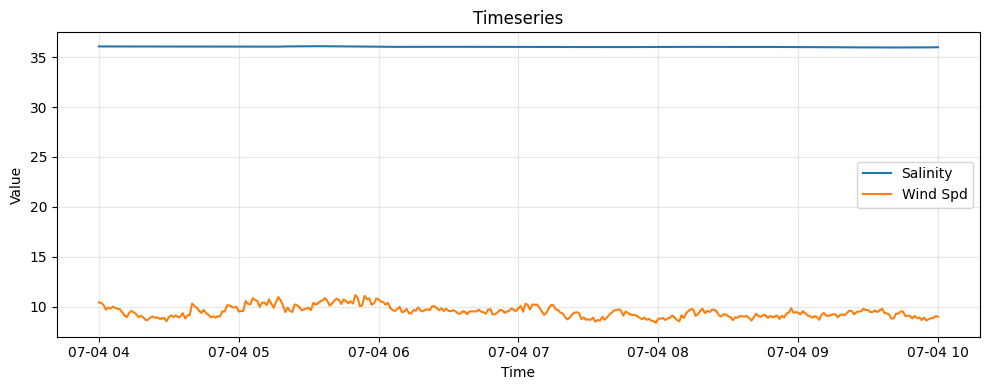


16) plot_map_tool


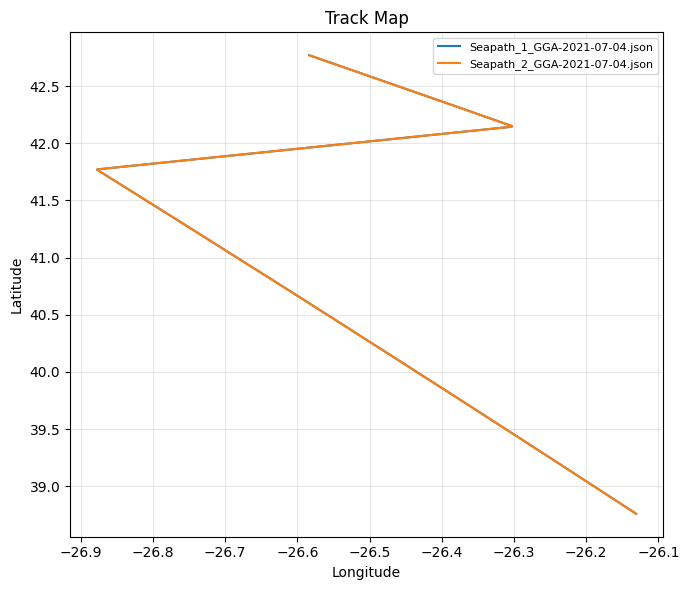


17) analysis_report_tool
{'n_variables': 3, 'total_rows': 5760}


,sensor_label,unit,n,mean,std,v_min,v_max,t_min,t_max
0,Chlorophyll Signal,counts,1440,63.13611,2.67905,60.0000,80.0000,2021-07-03 20:01:00-04:00,2021-07-04 20:00:00-04:00
1,Salinity,PSU,1440,35.92292,0.12627,35.6101,36.1381,2021-07-03 20:01:00-04:00,2021-07-04 20:00:00-04:00
2,Wind Spd,m/s,2880,8.28873,2.13711,2.7400,12.5900,2021-07-03 20:01:00-04:00,2021-07-04 20:00:00-04:00


In [86]:
from pathlib import Path
import matplotlib.pyplot as plt

from analysis_tools.common import get_default_paths
from analysis_tools.query_tools import (
    list_variables_tool,
    timeseries_fetch_tool,
    where_was_extreme_tool,
    summary_stats_tool,
    )
from analysis_tools.analysis import (
    correlation_tool,
    lag_correlation_tool,
    trend_tool,
    anomaly_detection_tool,
    )
from analysis_tools.geo_tools import (
    track_extract_tool,
    geo_join_tool,
    distance_speed_tool,
    )
from analysis_tools.qc_tools import (
    timestamp_alignment_tool,
    data_gaps_tool,
    sensor_qc_tool,
    )
from analysis_tools.report_tools import (
    plot_timeseries_tool,
    plot_map_tool,
    analysis_report_tool,
    )

paths = get_default_paths(Path.cwd(), "2021-07-04")
scalar = paths["scalar"]
geo = paths["geo"]
print("Using:")
print("-", scalar)
print("-", geo)

# Query tools
print("\n1) list_variables_tool")
vars_df = list_variables_tool(scalar)
display(vars_df.head(10))

print("\n2) timeseries_fetch_tool")
ts_df = timeseries_fetch_tool(scalar, ["Wind Spd", "Salinity"], start_time="2021-07-04T00:00:00", end_time="2021-07-04T03:00:00")
display(ts_df.head(10))

print("\n3) where_was_extreme_tool")
ext_tracks_df, ext_mean_df = where_was_extreme_tool(scalar, geo, "Salinity", mode="max")
display(ext_tracks_df)
display(ext_mean_df)

print("\n4) summary_stats_tool")
stats_df = summary_stats_tool(scalar, labels=["Wind Spd", "Salinity", "Chlorophyll Signal"])
display(stats_df)

# Analysis tools
print("\n5) correlation_tool")
corr_df_pkg = correlation_tool(scalar, ["Wind Spd", "Salinity", "External Temp"])
display(corr_df_pkg)

print("\n6) lag_correlation_tool")
lag_df_pkg, best_lag_pkg, best_corr_pkg = lag_correlation_tool(scalar, "Wind Spd", "Salinity", max_lag_steps=60)
print({"best_lag_steps": best_lag_pkg, "best_corr": best_corr_pkg})
display(lag_df_pkg.head(10))

print("\n7) trend_tool")
trend_pkg = trend_tool(scalar, "Wind Spd", rolling_window=60)
print({k: trend_pkg[k] for k in ["slope", "intercept", "n"]})

print("\n8) anomaly_detection_tool")
anoms_pkg = anomaly_detection_tool(scalar, "Wind Spd", z_threshold=3.0)
display(anoms_pkg.head(10))

# Geo tools
print("\n9) track_extract_tool")
track_df_pkg = track_extract_tool(geo, start_time="2021-07-04T00:00:00", end_time="2021-07-04T02:00:00")
display(track_df_pkg.head(10))

print("\n10) geo_join_tool")
joined_geo_df = geo_join_tool(scalar, geo, "Salinity")
display(joined_geo_df.head(10))

print("\n11) distance_speed_tool")
speed_df_pkg, speed_summary_pkg = distance_speed_tool(geo)
display(speed_summary_pkg)

# QC tools
print("\n12) timestamp_alignment_tool")
align_pkg = timestamp_alignment_tool(scalar, geo, variable="Salinity")
print(align_pkg)

print("\n13) data_gaps_tool")
gaps_pkg = data_gaps_tool(scalar, "Salinity", expected_step_seconds=60)
display(gaps_pkg.head(10))

print("\n14) sensor_qc_tool")
qc_flags_pkg = sensor_qc_tool(scalar, "Salinity", min_valid=30, max_valid=40)
display(qc_flags_pkg.head(10))

# Report tools
print("\n15) plot_timeseries_tool")
fig_ts = plot_timeseries_tool(scalar, ["Wind Spd", "Salinity"], start_time="2021-07-04T00:00:00", end_time="2021-07-04T06:00:00")
if fig_ts is not None:
    plt.show()

print("\n16) plot_map_tool")
fig_map = plot_map_tool(geo)
if fig_map is not None:
    plt.show()

print("\n17) analysis_report_tool")
report_pkg = analysis_report_tool(scalar, labels=["Wind Spd", "Salinity", "Chlorophyll Signal"])
print({k: v for k, v in report_pkg.items() if k != "stats"})
display(report_pkg["stats"])

## Step 14: LangGraph router demo (interactive)
This cell runs the `query_router_poc` graph on example questions and prints routed intent, extracted entities, and results.

In [87]:
from pathlib import Path

from analysis_tools.common import get_default_paths
from query_router_poc.router import run_query

paths = get_default_paths(Path.cwd(), "2021-07-04")
scalar_path_router = paths["scalar"]
geo_path_router = paths["geo"]

questions = [
    "when was salinity the highest",
    "where was salinity the highest",
    "what is the correlation between wind speed and salinity",
]

for question in questions:
    print(f"\nQ: {question}")
    result = run_query(question, scalar_path_router, geo_path_router)
    print("Intent:", result.intent)
    print("Entities:", result.entities)
    print("Answer:", result.answer_text)
    if result.table is not None:
        display(result.table.head(10))


Q: when was salinity the highest
Intent: when_max
Entities: {'variables': ['Salinity'], 'variable': 'Salinity'}
Answer: Salinity was highest at 2021-07-03 21:45:00-04:00 with value 36.1381.


,time,value,longitude,latitude
0,2021-07-03 21:45:00-04:00,36.1381,-26.205274,39.066854
1,2021-07-03 21:45:00-04:00,36.1381,-26.205275,39.066857



Q: where was salinity the highest
Intent: where_max
Entities: {'variables': ['Salinity'], 'variable': 'Salinity'}
Answer: Salinity was highest at (-26.205275, 39.066856) at 2021-07-03 21:45:00-04:00 (value=36.1381).


,time,sensor_label,value,nav_source_file,longitude,latitude
0,2021-07-03 21:45:00-04:00,Salinity,36.1381,OpenRVDAS/raw/Seapath_1_GGA-2021-07-04.json,-26.205274,39.066854
1,2021-07-03 21:45:00-04:00,Salinity,36.1381,OpenRVDAS/raw/Seapath_2_GGA-2021-07-04.json,-26.205275,39.066857



Q: what is the correlation between wind speed and salinity
Intent: correlation
Entities: {'variables': ['Salinity', 'Wind Spd'], 'x': 'Salinity', 'y': 'Wind Spd'}
Answer: Correlation between Salinity and Wind Spd is 0.1501.


sensor_label,Salinity,Wind Spd
sensor_label,,
Salinity,1.000000,0.150082
Wind Spd,0.150082,1.000000


## Step 15: Single-question router cell
Edit the `question` string and re-run this cell to test any free-text query through the LangGraph router.

In [88]:
from pathlib import Path
import importlib

from analysis_tools.common import get_default_paths
import query_router_poc.router as router_module

importlib.reload(router_module)
run_query = router_module.run_query

paths = get_default_paths(Path.cwd(), "2021-07-04")
scalar_path_router = paths["scalar"]
geo_path_router = paths["geo"]

# Change this line for ad-hoc testing
question = "in what location was salinity the highest"

result = run_query(question, scalar_path_router, geo_path_router)
print("Q:", question)
print("Intent:", result.intent)
print("Entities:", result.entities)
print("Answer:", result.answer_text)

if result.table is not None:
    display(result.table.head(20))

ImportError: cannot import name 'mean_tool' from 'analysis_tools.analysis' (c:\Users\liuja\Desktop\oceanX_data\analysis_tools\analysis.py)

## Step 16: Router semantic evaluation set
Run this cell to score intent-routing accuracy on a small paraphrase set and quickly spot regressions after parser edits.

In [ ]:
from pathlib import Path
import importlib
import pandas as pd

from analysis_tools.common import get_default_paths
import query_router_poc.router as router_module

importlib.reload(router_module)
run_query = router_module.run_query

paths = get_default_paths(Path.cwd(), "2021-07-04")
scalar_eval = paths["scalar"]
geo_eval = paths["geo"]

eval_cases = [
    {"question": "when was salinity the highest", "expected_intent": "when_max"},
    {"question": "what time did salinity peak", "expected_intent": "when_max"},
    {"question": "where was salinity the highest", "expected_intent": "where_max"},
    {"question": "in what location was salinity the highest", "expected_intent": "where_max"},
    {"question": "when was wind speed the lowest", "expected_intent": "when_min"},
    {"question": "when did wind speed reach minimum", "expected_intent": "when_min"},
    {"question": "where was salinity the lowest", "expected_intent": "where_min"},
    {"question": "location of minimum salinity", "expected_intent": "where_min"},
    {"question": "correlation between wind speed and salinity", "expected_intent": "correlation"},
    {"question": "how are salinity and wind speed related", "expected_intent": "correlation"},
    {"question": "tell me the time salinity hit its peak", "expected_intent": "when_max"},
    {"question": "at what time was chlorophyll maximum", "expected_intent": "when_max"},
    {"question": "what location corresponds to salinity peak", "expected_intent": "where_max"},
    {"question": "show the position of maximum wind speed", "expected_intent": "where_max"},
    {"question": "time of minimum chlorophyll", "expected_intent": "when_min"},
    {"question": "at what time was salinity at its minimum", "expected_intent": "when_min"},
    {"question": "position of lowest salinity", "expected_intent": "where_min"},
    {"question": "which place had the minimum wind speed", "expected_intent": "where_min"},
    {"question": "relationship between chlorophyll and wind speed", "expected_intent": "correlation"},
    {"question": "are temperature and salinity correlated", "expected_intent": "correlation"},
]

rows = []
for case in eval_cases:
    result = run_query(case["question"], scalar_eval, geo_eval)
    predicted_intent = result.intent
    rows.append(
        {
            "question": case["question"],
            "expected_intent": case["expected_intent"],
            "predicted_intent": predicted_intent,
            "match": predicted_intent == case["expected_intent"],
            "semantic_score": result.entities.get("semantic_score") if isinstance(result.entities, dict) else None,
            "answer_preview": (result.answer_text or "")[:90],
        }
    )

eval_df = pd.DataFrame(rows)
accuracy = float(eval_df["match"].mean()) if not eval_df.empty else 0.0

print(f"Router intent accuracy: {accuracy:.1%} ({eval_df['match'].sum()}/{len(eval_df)})")
display(eval_df)

print("\nFailures only:")
display(eval_df.loc[~eval_df["match"]].reset_index(drop=True))

Router intent accuracy: 100.0% (20/20)


,question,expected_intent,predicted_intent,match,semantic_score,answer_preview
0,when was salinity the highest,when_max,when_max,True,NaN,Salinity was highest at 2021-07-03 21:45:00-04...
1,what time did salinity peak,when_max,when_max,True,NaN,Salinity was highest at 2021-07-03 21:45:00-04...
2,where was salinity the highest,where_max,where_max,True,NaN,"Salinity was highest at (-26.205275, 39.066856..."
3,in what location was salinity the highest,where_max,where_max,True,NaN,"Salinity was highest at (-26.205275, 39.066856..."
4,when was wind speed the lowest,when_min,when_min,True,NaN,Wind Spd was lowest at 2021-07-04 14:07:00-04:...
5,when did wind speed reach minimum,when_min,when_min,True,NaN,Wind Spd was lowest at 2021-07-04 14:07:00-04:...
6,where was salinity the lowest,where_min,where_min,True,NaN,"Salinity was lowest at (-26.551083, 42.697729)..."
7,location of minimum salinity,where_min,where_min,True,NaN,"Salinity was lowest at (-26.551083, 42.697729)..."
8,correlation between wind speed and salinity,correlation,correlation,True,NaN,Correlation between Salinity and Wind Spd is 0...
9,how are salinity and wind speed related,correlation,correlation,True,0.625000,Correlation between Salinity and Wind Spd is 0...



Failures only:


,question,expected_intent,predicted_intent,match,semantic_score,answer_preview


## Step 17: CTD tool suite demo
This section runs the new CTD-oriented tools (label detection, CTD table prep, profile segmentation, MLD/thermocline, and QC flags).

In [ ]:
from pathlib import Path
import importlib

from analysis_tools.common import get_default_paths
import analysis_tools.ctd_tools as ctd_tools

importlib.reload(ctd_tools)

paths = get_default_paths(Path.cwd(), "2021-07-04")
scalar_ctd = paths["scalar"]

label_map_df = ctd_tools.ctd_detect_variable_labels_tool(scalar_ctd)
print("Detected CTD-relevant labels:")
display(label_map_df)

ctd_df = ctd_tools.ctd_prepare_dataframe_tool(scalar_ctd, require_core=False)
print(f"\nCTD prepared rows: {len(ctd_df):,}")
display(ctd_df.head(20))

if ctd_df.empty:
    print("No CTD-compatible rows available in this dataset.")
else:
    segment_df = ctd_tools.ctd_profile_segments_tool(ctd_df, min_points=10, min_depth_change=1.0)
    print("\nProfile segments:")
    display(segment_df.head(20))

    profile_summary_df = ctd_tools.ctd_profile_summary_tool(ctd_df, depth_bin_m=5.0)
    print("\nDepth-binned CTD summary:")
    display(profile_summary_df.head(20))

    mld_info = ctd_tools.mixed_layer_depth_tool(ctd_df)
    thermo_info = ctd_tools.thermocline_depth_tool(ctd_df)
    print("\nMixed Layer Depth:", mld_info)
    print("Thermocline estimate:", thermo_info)

    qc_flags_df = ctd_tools.ctd_qc_tool(ctd_df)
    print(f"\nQC flagged rows: {len(qc_flags_df):,}")
    display(qc_flags_df.head(20))

Detected CTD-relevant labels:


,variable,selected_label,status
0,temperature,Temperature,found
1,salinity,Salinity,found
2,depth,NaN,missing
3,pressure,NaN,missing
4,conductivity,Conductivity,found
5,oxygen,NaN,missing



CTD prepared rows: 1,440


sensor_label,time,temperature,salinity,depth,pressure,conductivity,oxygen
0,2021-07-04 00:01:00+00:00,21.11,36.0525,NaN,NaN,5.00313,NaN
1,2021-07-04 00:02:00+00:00,21.11,36.0522,NaN,NaN,5.00224,NaN
2,2021-07-04 00:03:00+00:00,21.11,36.0521,NaN,NaN,5.00194,NaN
3,2021-07-04 00:04:00+00:00,21.11,36.0523,NaN,NaN,5.00202,NaN
4,2021-07-04 00:05:00+00:00,21.11,36.0526,NaN,NaN,5.00194,NaN
5,2021-07-04 00:06:00+00:00,21.11,36.0528,NaN,NaN,5.00180,NaN
6,2021-07-04 00:07:00+00:00,21.11,36.0530,NaN,NaN,5.00156,NaN
7,2021-07-04 00:08:00+00:00,21.11,36.0531,NaN,NaN,5.00151,NaN
8,2021-07-04 00:09:00+00:00,21.10,36.0531,NaN,NaN,5.00099,NaN
9,2021-07-04 00:10:00+00:00,21.10,36.0533,NaN,NaN,5.00079,NaN



Profile segments:


""



Depth-binned CTD summary:


,depth_bin_m,n,temp_mean,sal_mean,cond_mean,oxy_mean



Mixed Layer Depth: {'mld_depth_m': nan, 'reason': 'missing_depth_or_temperature'}
Thermocline estimate: {'thermocline_depth_m': nan, 'dtemp_dz': nan, 'reason': 'insufficient_points'}

QC flagged rows: 31


sensor_label,time,temperature,salinity,depth,pressure,conductivity,oxygen,flag_temp_range,flag_sal_range,flag_depth_range,flag_temp_spike,flag_sal_spike,flag_any
0,2021-07-04 01:35:00+00:00,20.91,36.1134,NaN,NaN,5.01530,NaN,False,False,False,False,True,True
1,2021-07-04 01:36:00+00:00,20.99,36.1241,NaN,NaN,5.02174,NaN,False,False,False,False,True,True
2,2021-07-04 10:27:00+00:00,19.91,35.9619,NaN,NaN,4.91806,NaN,False,False,False,False,True,True
3,2021-07-04 15:36:00+00:00,20.40,35.7974,NaN,NaN,4.81934,NaN,False,False,False,False,True,True
4,2021-07-04 17:42:00+00:00,21.81,35.8274,NaN,NaN,4.83052,NaN,False,False,False,True,False,True
5,2021-07-04 17:43:00+00:00,22.86,35.8271,NaN,NaN,4.83026,NaN,False,False,False,True,False,True
6,2021-07-04 17:45:00+00:00,24.35,35.8258,NaN,NaN,4.82960,NaN,False,False,False,True,False,True
7,2021-07-04 17:46:00+00:00,25.20,35.8245,NaN,NaN,4.82941,NaN,False,False,False,True,False,True
8,2021-07-04 17:47:00+00:00,26.67,35.8225,NaN,NaN,4.82933,NaN,False,False,False,True,False,True
9,2021-07-04 17:48:00+00:00,27.76,35.8215,NaN,NaN,4.82905,NaN,False,False,False,True,False,True


## Step 18: Convert OpenRVDAS TXT files to JSON (missing-only)
This pipeline scans `OpenRVDAS` recursively and converts `.txt` files to `.json` only when the JSON file does not already exist.

In [ ]:
from pathlib import Path
import importlib

import analysis_tools.txt_to_json_pipeline as txt_json_pipeline

importlib.reload(txt_json_pipeline)

openrvdas_root = Path.cwd() / "OpenRVDAS"
conversion_df = txt_json_pipeline.convert_missing_openrvdas_json(openrvdas_root, overwrite=False)

print("Conversion summary:")
print(conversion_df["status"].value_counts(dropna=False))

print("\nConverted files preview:")
display(conversion_df.loc[conversion_df["status"] == "converted"].head(20))

print("\nErrors preview:")
display(conversion_df.loc[conversion_df["status"].astype(str).str.startswith("error:")].head(20))

Conversion summary:
status
skipped_exists    110
Name: count, dtype: int64

Converted files preview:


,txt_file,json_file,status,streams



Errors preview:


,txt_file,json_file,status,streams


## Step 19: Reload and run CTD tools for 2021-07-06
This reruns the daily pipeline for a CTD-relevant date and applies the CTD tool suite on the resulting scalar dataset.

In [ ]:
from pathlib import Path
import importlib

from analysis_tools.common import get_default_paths
import analysis_tools.ctd_tools as ctd_tools

importlib.reload(ctd_tools)

# Rebuild parquet outputs for CTD-relevant day
pipeline_result_0706 = run_daily_pipeline("2021-07-06")
paths_0706 = get_default_paths(Path.cwd(), "2021-07-06")
scalar_0706 = paths_0706["scalar"]

print("Using scalar dataset:", scalar_0706)

label_map_0706 = ctd_tools.ctd_detect_variable_labels_tool(scalar_0706)
print("\nDetected CTD labels (2021-07-06):")
display(label_map_0706)

ctd_df_0706 = ctd_tools.ctd_prepare_dataframe_tool(scalar_0706, require_core=False)
print(f"\nCTD prepared rows (2021-07-06): {len(ctd_df_0706):,}")
display(ctd_df_0706.head(20))

segment_df_0706 = ctd_tools.ctd_profile_segments_tool(ctd_df_0706, min_points=10, min_depth_change=1.0)
print("\nProfile segments (2021-07-06):")
display(segment_df_0706.head(20))

profile_summary_0706 = ctd_tools.ctd_profile_summary_tool(ctd_df_0706, depth_bin_m=5.0)
print("\nDepth-binned profile summary (2021-07-06):")
display(profile_summary_0706.head(20))

mld_0706 = ctd_tools.mixed_layer_depth_tool(ctd_df_0706)
thermo_0706 = ctd_tools.thermocline_depth_tool(ctd_df_0706)
print("\nMixed Layer Depth (2021-07-06):", mld_0706)
print("Thermocline estimate (2021-07-06):", thermo_0706)

qc_flags_0706 = ctd_tools.ctd_qc_tool(ctd_df_0706)
print(f"\nQC flagged rows (2021-07-06): {len(qc_flags_0706):,}")
display(qc_flags_0706.head(20))

Pipeline complete:
{'target_date': '2021-07-06', 'loaded_json_files': 16, 'failed_json_files': 0, 'scalar_rows': 42096, 'geospatial_rows': 2880, 'geospatial_speed_rows': 2880, 'lake_dir': 'c:\\Users\\liuja\\Desktop\\oceanX_data\\data\\cruise_2021_07_06'}


,dataset,n
0,scalar_timeseries,42096
1,navigation_track,2880
2,navigation_geo_speed,2880


Using scalar dataset: c:\Users\liuja\Desktop\oceanX_data\data\cruise_2021_07_06\scalar_timeseries.parquet

Detected CTD labels (2021-07-06):


,variable,selected_label,status
0,temperature,Temperature,found
1,salinity,Salinity,found
2,depth,HiPAP Depth,found
3,pressure,NaN,missing
4,conductivity,Conductivity,found
5,oxygen,NaN,missing



CTD prepared rows (2021-07-06): 1,440


sensor_label,time,temperature,salinity,depth,pressure,conductivity,oxygen
0,2021-07-06 00:01:00+00:00,15.4,35.6716,NaN,NaN,4.58553,NaN
1,2021-07-06 00:02:00+00:00,15.4,35.6710,NaN,NaN,4.58588,NaN
2,2021-07-06 00:03:00+00:00,15.4,35.6727,NaN,NaN,4.58520,NaN
3,2021-07-06 00:04:00+00:00,15.4,35.6751,NaN,NaN,4.58354,NaN
4,2021-07-06 00:05:00+00:00,15.4,35.6729,NaN,NaN,4.58382,NaN
5,2021-07-06 00:06:00+00:00,15.4,35.6747,NaN,NaN,4.58310,NaN
6,2021-07-06 00:07:00+00:00,15.4,35.6744,NaN,NaN,4.58325,NaN
7,2021-07-06 00:08:00+00:00,15.4,35.6749,NaN,NaN,4.58349,NaN
8,2021-07-06 00:09:00+00:00,15.4,35.6759,NaN,NaN,4.58381,NaN
9,2021-07-06 00:10:00+00:00,15.4,35.6796,NaN,NaN,4.58176,NaN


... (2 outputs left out)


Depth-binned profile summary (2021-07-06):


,depth_bin_m,n,temp_mean,sal_mean,cond_mean,oxy_mean
0,-30.0,1,16.710000,35.63370,4.633060,NaN
1,-25.0,1,16.700000,35.63350,4.633340,NaN
2,-20.0,1,16.690000,35.63340,4.633380,NaN
3,-15.0,1,16.600000,35.63370,4.633380,NaN
4,-5.0,2,16.640000,35.63475,4.633165,NaN
5,0.0,6,21.810000,35.61760,4.630537,NaN
6,5.0,3,21.890000,35.61260,4.635143,NaN
7,10.0,3,16.566667,35.63490,4.633300,NaN
8,15.0,1,16.700000,35.63530,4.631990,NaN
9,20.0,1,16.600000,35.63810,4.686770,NaN



Mixed Layer Depth (2021-07-06): {'mld_depth_m': 1.005, 'surface_temp_c': 16.705, 'threshold_temp_c': 16.505, 'reason': 'ok'}
Thermocline estimate (2021-07-06): {'thermocline_depth_m': 2383.0475454545453, 'dtemp_dz': -1650.1060886460853, 'reason': 'ok'}

QC flagged rows (2021-07-06): 43


sensor_label,time,temperature,salinity,depth,pressure,conductivity,oxygen,flag_temp_range,flag_sal_range,flag_depth_range,flag_temp_spike,flag_sal_spike,flag_any
0,2021-07-06 07:38:00+00:00,19.59,35.6044,NaN,NaN,4.60489,NaN,False,False,False,True,False,True
1,2021-07-06 07:51:00+00:00,18.47,35.6019,NaN,NaN,4.60966,NaN,False,False,False,True,False,True
2,2021-07-06 07:52:00+00:00,21.14,35.6027,NaN,NaN,4.60966,NaN,False,False,False,True,False,True
3,2021-07-06 08:12:00+00:00,22.46,35.6030,NaN,NaN,4.61182,NaN,False,False,False,True,False,True
4,2021-07-06 08:13:00+00:00,27.33,35.6030,NaN,NaN,4.61182,NaN,False,False,False,True,False,True
5,2021-07-06 08:14:00+00:00,31.04,35.6032,NaN,NaN,4.61174,NaN,False,False,False,True,False,True
6,2021-07-06 08:18:00+00:00,30.52,35.6033,NaN,NaN,4.61192,NaN,False,False,False,True,False,True
7,2021-07-06 08:19:00+00:00,28.21,35.6028,NaN,NaN,4.61210,NaN,False,False,False,True,False,True
8,2021-07-06 08:21:00+00:00,24.98,35.6029,NaN,NaN,4.61228,NaN,False,False,False,True,False,True
9,2021-07-06 08:31:00+00:00,25.49,35.6028,158.941545,NaN,4.61359,NaN,False,False,False,True,False,True


In [ ]:
# Step 20 quick diagnostic: depth coverage on 2021-07-06
import pandas as pd
from analysis_tools.query_tools import timeseries_fetch_tool

depth_raw_0706 = timeseries_fetch_tool(scalar_0706, ["HiPAP Depth"])
depth_raw_0706["time"] = pd.to_datetime(depth_raw_0706["time"], utc=True, errors="coerce")

print("HiPAP Depth raw rows:", len(depth_raw_0706))
print("HiPAP Depth non-null rows:", depth_raw_0706["value"].notna().sum())
if not depth_raw_0706.empty:
    print("HiPAP Depth time range:", depth_raw_0706["time"].min(), "to", depth_raw_0706["time"].max())
    print("First depth timestamp:", depth_raw_0706.loc[depth_raw_0706["value"].notna(), "time"].min())

print("\nCTD prepared depth non-null rows:", ctd_df_0706["depth"].notna().sum(), "out of", len(ctd_df_0706))
print("CTD prepared depth first non-null:", ctd_df_0706.loc[ctd_df_0706["depth"].notna(), "time"].min())

display(depth_raw_0706.head(10))
display(ctd_df_0706.loc[ctd_df_0706["depth"].notna(), ["time", "depth"]].head(10))

HiPAP Depth raw rows: 888
HiPAP Depth non-null rows: 888
HiPAP Depth time range: 2021-07-06 08:23:00+00:00 to 2021-07-06 17:40:00+00:00
First depth timestamp: 2021-07-06 08:23:00+00:00

CTD prepared depth non-null rows: 444 out of 1440
CTD prepared depth first non-null: 2021-07-06 08:23:00+00:00


,time,sensor_label,value,unit,source_file
0,2021-07-06 08:23:00+00:00,HiPAP Depth,6.157000,m,OpenRVDAS/raw/HiPAP_Nadir_PSIMSSB-2021-07-06.json
1,2021-07-06 08:23:00+00:00,HiPAP Depth,6.157000,m,OpenRVDAS/raw/HiPAP_CTD_PSIMSSB-2021-07-06.json
2,2021-07-06 08:24:00+00:00,HiPAP Depth,8.540583,m,OpenRVDAS/raw/HiPAP_Nadir_PSIMSSB-2021-07-06.json
3,2021-07-06 08:24:00+00:00,HiPAP Depth,8.540583,m,OpenRVDAS/raw/HiPAP_CTD_PSIMSSB-2021-07-06.json
4,2021-07-06 08:25:00+00:00,HiPAP Depth,2.435500,m,OpenRVDAS/raw/HiPAP_Nadir_PSIMSSB-2021-07-06.json
5,2021-07-06 08:25:00+00:00,HiPAP Depth,2.435500,m,OpenRVDAS/raw/HiPAP_CTD_PSIMSSB-2021-07-06.json
6,2021-07-06 08:26:00+00:00,HiPAP Depth,2.430636,m,OpenRVDAS/raw/HiPAP_CTD_PSIMSSB-2021-07-06.json
7,2021-07-06 08:26:00+00:00,HiPAP Depth,2.430636,m,OpenRVDAS/raw/HiPAP_Nadir_PSIMSSB-2021-07-06.json
8,2021-07-06 08:27:00+00:00,HiPAP Depth,2.936417,m,OpenRVDAS/raw/HiPAP_CTD_PSIMSSB-2021-07-06.json
9,2021-07-06 08:27:00+00:00,HiPAP Depth,2.936417,m,OpenRVDAS/raw/HiPAP_Nadir_PSIMSSB-2021-07-06.json


sensor_label,time,depth
502,2021-07-06 08:23:00+00:00,6.157000
503,2021-07-06 08:24:00+00:00,8.540583
504,2021-07-06 08:25:00+00:00,2.435500
505,2021-07-06 08:26:00+00:00,2.430636
506,2021-07-06 08:27:00+00:00,2.936417
507,2021-07-06 08:28:00+00:00,44.999083
508,2021-07-06 08:29:00+00:00,96.509545
509,2021-07-06 08:30:00+00:00,124.737833
510,2021-07-06 08:31:00+00:00,158.941545
511,2021-07-06 08:32:00+00:00,193.278750


## Step 21: Semantic routing method check
Run this to inspect which semantic method was used (`embedding` or `jaccard`) and the score/threshold per query.

In [ ]:
from pathlib import Path
import importlib
import pandas as pd

from analysis_tools.common import get_default_paths
import query_router_poc.router as router_module

importlib.reload(router_module)
run_query = router_module.run_query

paths = get_default_paths(Path.cwd(), "2021-07-04")
scalar_eval = paths["scalar"]
geo_eval = paths["geo"]

method_cases = [
    "in what location was salinity the highest",
    "time salinity peak",
    "how are salinity and wind speed related",
    "which place had the minimum wind speed",
]

rows = []
for question in method_cases:
    result = run_query(question, scalar_eval, geo_eval)
    entities = result.entities if isinstance(result.entities, dict) else {}
    rows.append(
        {
            "question": question,
            "intent": result.intent,
            "semantic_method": entities.get("semantic_method"),
            "semantic_score": entities.get("semantic_score"),
            "semantic_threshold": entities.get("semantic_threshold"),
            "answer_preview": (result.answer_text or "")[:100],
        }
    )

method_df = pd.DataFrame(rows)
display(method_df)

,question,intent,semantic_method,semantic_score,semantic_threshold,answer_preview
0,in what location was salinity the highest,where_max,NaN,NaN,NaN,"Salinity was highest at (-26.205275, 39.066856..."
1,time salinity peak,when_max,jaccard,0.600,0.3,Salinity was highest at 2021-07-03 21:45:00-04...
2,how are salinity and wind speed related,correlation,jaccard,0.625,0.3,Correlation between Salinity and Wind Spd is 0...
3,which place had the minimum wind speed,where_min,NaN,NaN,NaN,"Wind Spd was lowest at (-26.791571, 41.826820)..."


## Step 22: Interactive full pipeline + router decision trace (expanded intents)
Set the inputs in the next cell, then run it to execute the daily data pipeline and route your query while printing decisions for the expanded intent set (query, analysis, geo, QC, and CTD).

In [95]:
from pathlib import Path
import importlib
import pandas as pd

from analysis_tools.common import get_default_paths
import analysis_tools.analysis as analysis_module
import query_router_poc.router as router_module

# --------- User inputs ---------
trace_target_date = "2021-07-06"
trace_query = "where is my highest salinity?"
trace_convert_missing_txt = False
trace_rebuild_pipeline = True
trace_show_intent_catalog = True
# -------------------------------

print("=== Step A: Optional TXT->JSON conversion ===")
if trace_convert_missing_txt:
    import analysis_tools.txt_to_json_pipeline as txt_json_pipeline
    importlib.reload(txt_json_pipeline)
    openrvdas_root = Path.cwd() / "OpenRVDAS"
    conversion_df_trace = txt_json_pipeline.convert_missing_openrvdas_json(openrvdas_root, overwrite=False)
    print(conversion_df_trace["status"].value_counts(dropna=False))
else:
    print("Skipped conversion (trace_convert_missing_txt=False)")

print("\n=== Step B: Daily pipeline build/check ===")
if trace_rebuild_pipeline:
    pipeline_trace = run_daily_pipeline(trace_target_date)
    print("Pipeline summary:", pipeline_trace["summary"])
else:
    print("Skipped run_daily_pipeline (trace_rebuild_pipeline=False)")

print("\n=== Step C: Resolve dataset paths ===")
paths_trace = get_default_paths(Path.cwd(), trace_target_date)
scalar_trace = paths_trace["scalar"]
geo_trace = paths_trace["geo"]
print("scalar:", scalar_trace)
print("geo:", geo_trace)

print("\n=== Step D: Reload analysis + router modules ===")
importlib.reload(analysis_module)
importlib.reload(router_module)
run_query = router_module.run_query

print("\n=== Step E: Parser decision trace (expanded) ===")
q_norm = router_module._normalize_question(trace_query)
vars_found = router_module._extract_variables(q_norm)
semantic_intent, semantic_score, semantic_method = router_module._semantic_intent_match(q_norm)
semantic_threshold = (
    router_module.EMBEDDING_SCORE_THRESHOLD
    if semantic_method == "embedding"
    else router_module.JACCARD_SCORE_THRESHOLD
)
semantic_pass = semantic_score >= semantic_threshold

parsed_state = router_module.parse_intent_node(
    {
        "question": trace_query,
        "scalar_path": str(scalar_trace),
        "geo_path": str(geo_trace),
    }
)
routed_intent = parsed_state.get("intent")
routed_entities = parsed_state.get("entities", {})

decision_source = "rule"
if routed_entities.get("semantic_method"):
    decision_source = "semantic"
elif routed_intent == "unknown":
    decision_source = "none"

print("Question:", trace_query)
print("Normalized:", q_norm)
print("Extracted variables:", vars_found)
print("Semantic candidate:", {
    "intent": semantic_intent,
    "method": semantic_method,
    "score": semantic_score,
    "threshold": semantic_threshold,
    "pass": semantic_pass,
})
print("Final routed intent:", routed_intent)
print("Decision source:", decision_source)
print("Final entities:", routed_entities)

if trace_show_intent_catalog:
    print("\nSupported intents:")
    for intent_name in sorted(router_module.INTENT_TEMPLATES.keys()):
        print("-", intent_name)

print("\n=== Step F: Execute routed query ===")
result_trace = run_query(trace_query, scalar_trace, geo_trace)

print("Answer:", result_trace.answer_text)
if result_trace.table is not None:
    print(f"Returned rows: {len(result_trace.table):,}")
    display(result_trace.table.head(20))
else:
    print("No result table returned.")

if result_trace.intent == "relationship_direction" and result_trace.table is not None and not result_trace.table.empty:
    rel_row = result_trace.table.iloc[0].to_dict()
    print("\nRelationship-direction details:")
    print({
        "direction": rel_row.get("direction"),
        "slope_y_per_x": rel_row.get("slope_y_per_x"),
        "pearson_r": rel_row.get("pearson_r"),
        "spearman_r": rel_row.get("spearman_r"),
        "n": rel_row.get("n"),
        "x_label": rel_row.get("x_label"),
        "y_label": rel_row.get("y_label"),
    })

print("\n=== Step G: Compact trace summary ===")
summary_row = {
    "date": trace_target_date,
    "query": trace_query,
    "routed_intent": routed_intent,
    "decision_source": decision_source,
    "semantic_method": routed_entities.get("semantic_method"),
    "semantic_score": routed_entities.get("semantic_score"),
    "rows_returned": 0 if result_trace.table is None else len(result_trace.table),
}

if result_trace.intent == "relationship_direction" and result_trace.table is not None and not result_trace.table.empty:
    rel_row = result_trace.table.iloc[0].to_dict()
    summary_row.update({
        "direction": rel_row.get("direction"),
        "slope_y_per_x": rel_row.get("slope_y_per_x"),
        "pearson_r": rel_row.get("pearson_r"),
        "spearman_r": rel_row.get("spearman_r"),
        "n": rel_row.get("n"),
        "x_label": rel_row.get("x_label"),
        "y_label": rel_row.get("y_label"),
    })

trace_summary_df = pd.DataFrame([summary_row])
display(trace_summary_df)

=== Step A: Optional TXT->JSON conversion ===
Skipped conversion (trace_convert_missing_txt=False)

=== Step B: Daily pipeline build/check ===
Pipeline complete:
{'target_date': '2021-07-06', 'loaded_json_files': 16, 'failed_json_files': 0, 'scalar_rows': 42096, 'geospatial_rows': 2880, 'geospatial_speed_rows': 2880, 'lake_dir': 'c:\\Users\\liuja\\Desktop\\oceanX_data\\data\\cruise_2021_07_06'}


,dataset,n
0,scalar_timeseries,42096
1,navigation_track,2880
2,navigation_geo_speed,2880


Pipeline summary: {'target_date': '2021-07-06', 'loaded_json_files': 16, 'failed_json_files': 0, 'scalar_rows': 42096, 'geospatial_rows': 2880, 'geospatial_speed_rows': 2880, 'lake_dir': 'c:\\Users\\liuja\\Desktop\\oceanX_data\\data\\cruise_2021_07_06'}

=== Step C: Resolve dataset paths ===
scalar: c:\Users\liuja\Desktop\oceanX_data\data\cruise_2021_07_06\scalar_timeseries.parquet
geo: c:\Users\liuja\Desktop\oceanX_data\data\cruise_2021_07_06\navigation_track.parquet

=== Step D: Reload analysis + router modules ===

=== Step E: Parser decision trace (expanded) ===
Question: where is my highest salinity?
Normalized: where is my highest salinity?
Extracted variables: ['Salinity']
Semantic candidate: {'intent': 'where_max', 'method': 'jaccard', 'score': 0.42857142857142855, 'threshold': 0.3, 'pass': True}
Final routed intent: where_max
Decision source: rule
Final entities: {'variables': ['Salinity'], 'variable': 'Salinity'}

Supported intents:
- anomaly_detection
- bounds
- correlation


,time,sensor_label,value,nav_source_file,longitude,latitude
0,2021-07-06 16:15:00-04:00,Salinity,35.72,OpenRVDAS/raw/Seapath_1_GGA-2021-07-06.json,-27.287742,45.671905
1,2021-07-06 16:15:00-04:00,Salinity,35.72,OpenRVDAS/raw/Seapath_2_GGA-2021-07-06.json,-27.287738,45.671906



=== Step G: Compact trace summary ===


,date,query,routed_intent,decision_source,semantic_method,semantic_score,rows_returned
0,2021-07-06,where is my highest salinity?,where_max,rule,None,None,2


In [90]:

# Demonstrate Summary Statistics Tools
print("=" * 60)
print("SUMMARY STATISTICS TOOLS DEMONSTRATION")
print("=" * 60)

# Example queries for each new tool
stats_queries = [
    "mean of salinity",
    "median wind speed",
    "mode of salinity",
    "bounds of temperature",
]

print("\n### Executing Summary Statistics Queries ###\n")

for q in stats_queries:
    print(f"\nQuery: {q}")
    print("-" * 50)
    
    result1 = run_query(q, scalar_trace, geo_trace)
    print(f"Intent: {result1.intent}")
    print(f"Answer: {result1.answer_text}")
    
    if result1.table is not None and not result1.table.empty:
        display(result1.table)
    else:
        print("No data returned.")

print("\n" + "=" * 60)
print("SUMMARY STATISTICS TOOLS SUCCESSFULLY INTEGRATED")
print("=" * 60)
print("\nAvailable summary statistics tools:")
print("  1. mean_tool          - Compute mean values")
print("  2. median_tool        - Compute median values")
print("  3. mode_tool          - Compute mode values (most frequent)")
print("  4. bounds_tool        - Compute min/max bounds and range")
print("\nAll tools support single or multiple variables via labels parameter.")

SUMMARY STATISTICS TOOLS DEMONSTRATION

### Executing Summary Statistics Queries ###


Query: mean of salinity
--------------------------------------------------
Intent: mean
Answer: Computed mean for 1 variable(s).


,sensor_label,mean
0,Salinity,35.633685



Query: median wind speed
--------------------------------------------------
Intent: median
Answer: Computed median for 1 variable(s).


,sensor_label,median
0,Wind Spd,2.36



Query: mode of salinity
--------------------------------------------------
Intent: mode
Answer: Computed mode for 1 variable(s).


,sensor_label,mode,count
0,Salinity,35.603,10



Query: bounds of temperature
--------------------------------------------------
Intent: bounds
Answer: Computed bounds for 1 variable(s).


,sensor_label,min_value,max_value,range
0,Temperature,15.3,33.22,17.92



SUMMARY STATISTICS TOOLS SUCCESSFULLY INTEGRATED

Available summary statistics tools:
  1. mean_tool          - Compute mean values
  2. median_tool        - Compute median values
  3. mode_tool          - Compute mode values (most frequent)
  4. bounds_tool        - Compute min/max bounds and range

All tools support single or multiple variables via labels parameter.
